<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-12/lab-070b-quantum-autoencoder.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

# Lab 070b. A quantum autoencoder for ground states of the Ising chain

A classical autoencoder squeezes its input through a narrow layer and is trained to reproduce the input from this compressed code. A quantum autoencoder (QAE) does the same with quantum states [1]. A circuit, the encoder, acts on a state of $N$ qubits and is trained so that $k$ of the qubits always end in $|0\rangle$. These $k$ trash qubits then carry no information and can be reset, and the remaining $N-k$ latent qubits hold the compressed state. Running the encoder backwards on the latent qubits and $k$ fresh qubits in $|0\rangle$ restores the input.

We are given the exact ground states of the transverse-field Ising chain of $N=6$ qubits, the model of the VQE notebook. We train one encoder on ground states from the paramagnetic phase, freeze it and apply it to ground states at all fields between $h=0$ and $h=2$. States that resemble the training states are compressed well, and the others are compressed badly, so the failure of compression serves as an anomaly score that locates the change of phase without any order parameter [2]. We compare this score with the exact half-chain entanglement entropy and ask how much of it is physics and how much is a property of the trained circuit.

All results are exact state-vector simulations. On a device the trash fidelity would be estimated from measured bit strings of the trash qubits. Sections 1 to 9 form the classroom route and run in about one and a half minutes on a laptop CPU. Section 3 follows a single state through a hand-built autoencoder and introduces the Schmidt rank, the quantity that decides whether a state can be compressed. Section 10 is an optional study with eight qubits that maps compressibility and anomaly scores across the phase diagrams of the Ising chain and of the XXZ chain in a field and takes between four and ten more minutes, depending on the load of the machine. Section 11 lists exercises for home.

## 1. Double-precision arithmetic

We work in double precision on the CPU. JAX computes the circuits, the gradients and the training loops, NumPy builds the Hamiltonian and the exact references, and Matplotlib draws the figures. Every random seed is fixed.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"          # small calculations, never the GPU
import json, time, itertools
from pathlib import Path
import numpy as np
import scipy.sparse as sp
import jax
import jax.numpy as jnp
from jax import lax
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

jax.config.update("jax_enable_x64", True)
TOL = 1e-10
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
RES = Path("classroom_results"); RES.mkdir(exist_ok=True)
NAVY, BLUE, ORANGE, GRAY, GREEN = "#002B5C", "#3E8FD0", "#D35A05", "#5A6270", "#1B7F36"
plt.rcParams.update({"font.size": 13, "axes.labelsize": 13, "xtick.labelsize": 12, "ytick.labelsize": 12,
                     "legend.fontsize": 11.5, "figure.figsize": (4.8, 3.2), "axes.spines.top": False,
                     "axes.spines.right": False, "savefig.bbox": "tight", "pdf.fonttype": 42, "ps.fonttype": 42})
def save(fig, name):
    fig.savefig(FIG / f"{name}.pdf"); fig.savefig(FIG / f"{name}.png", dpi=200)
started = time.perf_counter()
RESULTS = {}
print("JAX", jax.__version__, "| devices:", jax.devices())

JAX 0.11.0 | devices: [CpuDevice(id=0)]


## 2. The quantum autoencoder

A classical autoencoder maps an input $\mathbf x$ to a short code $\mathbf z$ with an encoder network and maps the code back with a decoder network. Training lowers the reconstruction error averaged over a data set, and it succeeds when the data occupy a low-dimensional part of the input space. The quantum version keeps this structure but uses unitary operations. We split the register into $N-k$ latent qubits and $k$ trash qubits, here the last $k$ qubits of the chain. The QAE then acts in three steps.

1. The encoder $\hat U(\boldsymbol\theta)$, a circuit with angles $\boldsymbol\theta$, acts on the input $|\psi\rangle$ of all $N$ qubits.
2. The trash qubits are reset to $|0\rangle$, which discards whatever they held.
3. The decoder $\hat U^\dagger(\boldsymbol\theta)$, the encoder run backwards, acts on the latent qubits and the fresh trash qubits and returns the output state.

When the encoder leaves the trash qubits in $|0\dots0\rangle$ for every input, $\hat U|\psi\rangle=|\phi\rangle\otimes|0\dots0\rangle$ with a latent state $|\phi\rangle$ of $N-k$ qubits, the reset changes nothing and the decoder returns $|\psi\rangle$ exactly. The quantity to train is therefore how close the trash qubits are to $|0\dots0\rangle$ after the encoder. The cell below draws the circuit for $N=6$ and $k=2$.

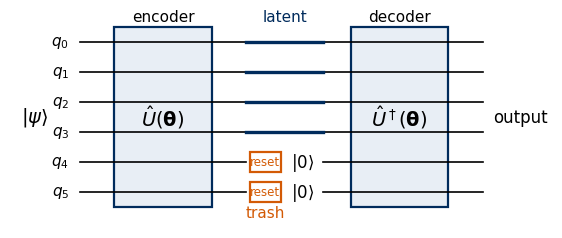

In [2]:
fig, ax = plt.subplots(figsize=(7.0, 2.8))
ys = np.arange(6)[::-1] * 0.5
for i, y in enumerate(ys):
    trash = i >= 4
    ax.plot([0.6, 3.0], [y, y], color="black", lw=1.2)
    ax.plot([4.1, 6.4], [y, y], color="black", lw=1.2)
    if trash:
        ax.add_patch(Rectangle((3.05, y - 0.17), 0.45, 0.34, fc="white", ec=ORANGE, lw=1.6))
        ax.text(3.27, y, "reset", ha="center", va="center", fontsize=8.5, color=ORANGE)
        ax.text(3.8, y, r"$|0\rangle$", ha="center", va="center", fontsize=12)
    else:
        ax.plot([3.0, 4.1], [y, y], color=NAVY, lw=2.4)
    ax.text(0.45, y, f"$q_{i}$", ha="right", va="center", fontsize=11)
for x0, label in ((1.1, r"$\hat U(\mathbf{\theta})$"), (4.5, r"$\hat U^\dagger(\mathbf{\theta})$")):
    ax.add_patch(Rectangle((x0, ys[-1] - 0.25), 1.4, ys[0] - ys[-1] + 0.5, fc="#E8EEF5", ec=NAVY, lw=1.6))
    ax.text(x0 + 0.7, ys.mean(), label, ha="center", va="center", fontsize=14)
ax.text(0.15, ys.mean(), r"$|\psi\rangle$", ha="right", va="center", fontsize=14)
ax.text(6.55, ys.mean(), "output", ha="left", va="center", fontsize=12)
ax.text(3.55, ys[0] + 0.35, "latent", ha="center", color=NAVY, fontsize=11)
ax.text(1.8, ys[0] + 0.35, "encoder", ha="center", fontsize=11); ax.text(5.2, ys[0] + 0.35, "decoder", ha="center", fontsize=11)
ax.text(3.27, ys[-1] - 0.42, "trash", ha="center", color=ORANGE, fontsize=11)
ax.set_xlim(-0.4, 7.4); ax.set_ylim(-0.6, 3.0); ax.axis("off")
save(fig, "fig_lab070b_circuit"); plt.show()

The latent qubits (navy) pass from the encoder to the decoder untouched, while the two trash qubits (orange) are reset and re-enter the decoder in $|0\rangle$.

## 3. Following the state through the autoencoder

The reset of the trash qubits discards information, so between encoder and decoder the register is in general in a mixed state. We therefore follow the density matrix through the five stages of the autoencoder. For a pure input $|\psi\rangle$ of $N$ qubits they are
$$\hat\rho_{\rm in}=|\psi\rangle\langle\psi|\ \xrightarrow{\ \hat U\ }\ \hat\rho_1=\hat U\hat\rho_{\rm in}\hat U^\dagger\ \xrightarrow{\ \mathrm{Tr}_{\rm trash}\ }\ \hat\rho_{\rm lat}=\mathrm{Tr}_{\rm trash}\,\hat\rho_1\ \xrightarrow{\ \text{reset}\ }\ \hat\rho_2=\hat\rho_{\rm lat}\otimes|0\dots0\rangle\langle0\dots0|\ \xrightarrow{\ \hat U^\dagger\ }\ \hat\rho_{\rm out}=\hat U^\dagger\hat\rho_2\hat U . \tag{1}$$
The partial trace $\mathrm{Tr}_{\rm trash}$ sums over the basis states of the trash qubits and leaves the density matrix $\hat\rho_{\rm lat}$ of the $N-k$ latent qubits, which contains every prediction for measurements on the latent qubits alone. The reset replaces the trash qubits by $|0\dots0\rangle$. The quality of the reconstruction is the fidelity
$$F=\langle\psi|\hat\rho_{\rm out}|\psi\rangle , \tag{2}$$
the probability that the output passes a test for being the input state.

A formula for $F$ follows from splitting the encoded state into branches labelled by the bit strings $t$ of the trash qubits,
$$\hat U|\psi\rangle=\sum_{t}|\alpha_t\rangle\otimes|t\rangle , \tag{3}$$
where $t$ runs over the $2^k$ bit strings and the latent vectors $|\alpha_t\rangle$ are unnormalised, with $\sum_t\langle\alpha_t|\alpha_t\rangle=1$. The partial trace gives $\hat\rho_{\rm lat}=\sum_t|\alpha_t\rangle\langle\alpha_t|$, and since $\langle\psi|\hat U^\dagger$ meets the fresh trash qubits only through its branch $t=0\dots0$,
$$F=\sum_t|\langle\alpha_0|\alpha_t\rangle|^2 . \tag{4}$$
If the encoder leaves the trash qubits in $|0\dots0\rangle$, only $|\alpha_0\rangle$ survives, $\hat\rho_{\rm lat}$ is pure, and $F=1$. Otherwise the latent and trash qubits are entangled, the purity $\mathrm{Tr}\,\hat\rho_{\rm lat}^2$ drops below one, and part of the state is lost at the reset. The weight $F_{\rm trash}=\langle\alpha_0|\alpha_0\rangle$ of the branch $t=0\dots0$ is the trash fidelity.

On a device the encoder is trained from measured bit strings of the trash qubits. The trash Hamming distance $D_H=\frac1k\sum_{j\in{\rm trash}}\langle\hat n_j\rangle$, with the occupation $\hat n_j=(\hat I-\hat Z_j)/2$, is the mean number of $1$s per trash qubit. The term $t=0\dots0$ of equation (4) alone gives $F\ge F_{\rm trash}^2$. The probability $1-F_{\rm trash}$ that at least one trash bit is $1$ cannot exceed the sum $kD_H$ of the probabilities of the single bits, so
$$F\ \ge\ \max\big(0,\,1-kD_H\big)^2 , \tag{5}$$
and a small Hamming distance guarantees a faithful reconstruction.

A three-qubit example makes the stages concrete. Qubit 0 is the latent qubit and qubits 1 and 2 are the trash, $k=2$. The input
$$|\psi\rangle\propto\cos a\,|000\rangle+\sin a\,|111\rangle+\varepsilon\,|100\rangle$$
is a weighted cat state of three qubits with an admixture of weight $\varepsilon$. As encoder we take two controlled-NOT gates with qubit 0 as control, first on target 1 and then on target 2. They copy the value of qubit 0 into the trash qubits a second time, which undoes the correlation of the cat state, $|000\rangle\to|000\rangle$ and $|111\rangle\to|100\rangle$, so for $\varepsilon=0$ the encoded state is $(\cos a|0\rangle+\sin a|1\rangle)\otimes|00\rangle$ and compression is perfect. The admixture is mapped to $|1\rangle\otimes|11\rangle$ and lands in the branch $t=11$. The cell computes all matrices of equation (1) for $a=\pi/5$ and $\varepsilon=0$ and $0.3$ and checks equations (4) and (5).

epsilon = 0.0: purity of rho_lat = 1.0000, F = 1.0000, D_H = 0.0000, bound (5) = 1.0000
epsilon = 0.3: purity of rho_lat = 0.9008, F = 0.8679, D_H = 0.0826, bound (5) = 0.6970


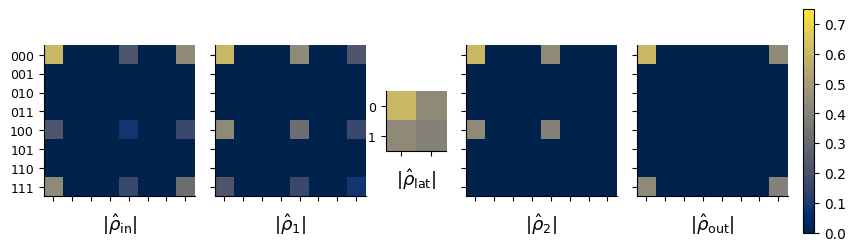

In [3]:
def ket(bits):
    v = np.zeros(2 ** len(bits)); v[int(bits, 2)] = 1.0                 # qubit 0 is the leftmost bit
    return v

def cnot(control, target, n):
    # permutation matrix of a controlled-NOT gate on n qubits
    M = np.zeros((2 ** n, 2 ** n))
    for i in range(2 ** n):
        b = [(i >> (n - 1 - q)) & 1 for q in range(n)]
        if b[control]:
            b[target] ^= 1
        M[int("".join(map(str, b)), 2), i] = 1.0
    return M

def follow_state(psi, U, k):
    """The five density matrices of equation (1); the trash qubits are the last k."""
    n_lat = 2 ** (len(np.binary_repr(len(psi) - 1)) - k)
    rho_in = np.outer(psi, psi.conj())
    rho_1 = U @ rho_in @ U.conj().T
    rho_lat = np.einsum("atbt->ab", rho_1.reshape(n_lat, 2 ** k, n_lat, 2 ** k))   # partial trace over the trash
    reset = np.zeros((2 ** k, 2 ** k)); reset[0, 0] = 1.0
    rho_2 = np.kron(rho_lat, reset)
    rho_out = U.conj().T @ rho_2 @ U
    return dict(rho_in=rho_in, rho_1=rho_1, rho_lat=rho_lat, rho_2=rho_2, rho_out=rho_out)

A_EX, EPS_EX, K_EX = np.pi / 5, 0.3, 2
U_EX = cnot(0, 2, 3) @ cnot(0, 1, 3)                                        # first CNOT(0 -> 1), then CNOT(0 -> 2)
assert np.allclose(U_EX @ ket("111"), ket("100")) and np.allclose(U_EX @ ket("100"), ket("111"))

def example_state(eps):
    v = np.cos(A_EX) * ket("000") + np.sin(A_EX) * ket("111") + eps * ket("100")
    return v / np.linalg.norm(v)

FLOW = {}
for eps in (0.0, EPS_EX):
    psi_ex = example_state(eps)
    st = follow_state(psi_ex, U_EX, K_EX)
    for r in st.values():
        assert abs(np.trace(r) - 1) < TOL and np.allclose(r, r.conj().T) and np.linalg.eigvalsh(r).min() > -TOL
    F = float(np.real(psi_ex.conj() @ st["rho_out"] @ psi_ex))                       # equation (2)
    alpha = (U_EX @ psi_ex).reshape(2, 2 ** K_EX)                                  # column t is |alpha_t>, equation (3)
    F_branches = float(np.sum(np.abs(alpha[:, 0].conj() @ alpha) ** 2))           # equation (4)
    purity = float(np.real(np.trace(st["rho_lat"] @ st["rho_lat"])))
    p1 = np.real(np.diag(st["rho_1"])).reshape(2, 2, 2)                           # probabilities of the bit strings b0 b1 b2
    D_H = (p1[:, 1, :].sum() + p1[:, :, 1].sum()) / K_EX                         # mean number of 1s per trash qubit
    assert abs(F - F_branches) < TOL                                              # equation (4)
    assert F >= max(0.0, 1 - K_EX * D_H) ** 2 - TOL                               # bound (5)
    assert abs(F - (1 + eps ** 2 * np.sin(A_EX) ** 2) / (1 + eps ** 2) ** 2) < TOL  # equation (4) evaluated for this input
    FLOW[eps] = dict(F=F, purity=purity, D_H=D_H, bound=max(0.0, 1 - K_EX * D_H) ** 2, states=st)
    print(f"epsilon = {eps:.1f}: purity of rho_lat = {purity:.4f}, F = {F:.4f}, D_H = {D_H:.4f}, "
          f"bound (5) = {FLOW[eps]['bound']:.4f}")
RESULTS["state_flow"] = {str(eps): {key: v for key, v in d.items() if key != "states"} for eps, d in FLOW.items()}

fig, axs = plt.subplots(1, 5, figsize=(10.0, 2.9), gridspec_kw=dict(width_ratios=[4, 4, 1.6, 4, 4], wspace=0.15))
labels = [r"$|\hat\rho_{\rm in}|$", r"$|\hat\rho_1|$", r"$|\hat\rho_{\rm lat}|$", r"$|\hat\rho_2|$", r"$|\hat\rho_{\rm out}|$"]
for ax, key, lab in zip(axs, ["rho_in", "rho_1", "rho_lat", "rho_2", "rho_out"], labels):
    im = ax.imshow(np.abs(FLOW[EPS_EX]["states"][key]), cmap="cividis", vmin=0, vmax=0.75)
    n_b = FLOW[EPS_EX]["states"][key].shape[0]
    nq = int(np.log2(n_b))
    ax.set_xticks(range(n_b)); ax.set_yticks(range(n_b))
    ax.set_yticklabels([np.binary_repr(i, nq) for i in range(n_b)] if key in ("rho_in", "rho_lat") else [], fontsize=9)
    ax.set_xticklabels([])
    ax.set_xlabel(lab, fontsize=13)
cb = fig.colorbar(im, ax=axs, fraction=0.02, pad=0.02); cb.ax.tick_params(labelsize=10)
save(fig, "fig_lab070b_state_flow"); plt.show()

The figure shows the absolute values of the matrix elements of the five density matrices for $\varepsilon=0.3$. Rows and columns follow the bit strings in the order printed on the left, and the latent matrix has the rows $0$ and $1$ of qubit 0. The input has the four corner elements of the cat state and a weak row and column of the admixture $|100\rangle$. After the encoder, $\hat\rho_1$ has its weight mostly in the block of trash bits $00$ (rows $000$ and $100$), and the admixture sits alone in row $111$. The partial trace leaves a $2\times2$ latent matrix, which is no longer pure because the admixture is entangled with the trash. After the reset, $\hat\rho_2$ has weight only in rows whose trash bits are $00$, and the decoder turns it into $\hat\rho_{\rm out}$, which keeps the cat-state corners and has lost the admixture row. For $\varepsilon=0$ the latent state is pure and $F=1$. For $\varepsilon=0.3$ the latent purity and the fidelity drop below one, and the fidelity lies well above the guarantee (5) given by the Hamming distance.

### The Schmidt rank

Whether a reset loses information depends on the entanglement between the latent and the trash qubits, and the Schmidt decomposition describes this entanglement completely. Every pure state of two parts $A$ and $B$ can be written as
$$|\psi\rangle=\sum_{r=1}^{\chi}s_r\,|a_r\rangle_A\otimes|b_r\rangle_B , \tag{6}$$
with orthonormal states $|a_r\rangle$ of $A$, orthonormal states $|b_r\rangle$ of $B$, Schmidt coefficients $s_1\ge s_2\ge\dots\ge s_\chi>0$ and $\sum_rs_r^2=1$. The number of terms $\chi$ is the Schmidt rank. A product state has $\chi=1$, and the larger $\chi$ and the more even the coefficients, the more entangled the parts are. To compute the decomposition, we reshape the state vector into the $d_A\times d_B$ matrix $\psi_{ab}$, with $a$ the bit string of $A$ and $b$ that of $B$. Its singular value decomposition $\psi_{ab}=\sum_rU_{ar}s_rV^\dagger_{rb}$ gives the coefficients as singular values, $|a_r\rangle$ as the columns of $U$ and $|b_r\rangle$ as the complex conjugates of the rows of $V^\dagger$. The reduced density matrix of $B$ is $\hat\rho_B=\sum_rs_r^2|b_r\rangle\langle b_r|$, so $\chi$ is also its rank, and the purity of either part is $\sum_rs_r^4$.

The Schmidt rank sets how far part $B$ can be compressed by a unitary $\hat W_B$ acting on $B$ alone. Such a unitary can rotate the $\chi$ states $|b_r\rangle$ into the basis states $|r\rangle\otimes|0\dots0\rangle$, in which $r=0,\dots,\chi-1$ is written in binary on the first $m=\lceil\log_2\chi\rceil$ qubits of $B$ and the remaining qubits of $B$ are all $0$. These qubits are then trash and can be reset without loss. Fewer than $m$ qubits cannot suffice, since a unitary on $B$ keeps the rank $\chi$ of $\hat\rho_B$, whereas a state of fewer qubits times $|0\dots0\rangle$ has a rank below $2^m$. If only $m'$ qubits of $B$ are kept, the largest possible probability of finding the remaining qubits in $0$ is the sum of the $2^{m'}$ largest $s_r^2$, the bound used for families in Section 5 [3].

The cell builds a random state of $N=6$ qubits with $A$ the first two and $B$ the last four qubits and with Schmidt rank $\chi=3$. It constructs $\hat W_B$ from the singular value decomposition, checks that two qubits of $B$ hold the whole state and that the sum of the largest $s_r^2$ is reached for every number of kept qubits. It also prints the Schmidt spectrum across the latent and trash qubits of the encoded three-qubit example.

epsilon = 0.0: squared Schmidt coefficients after the encoder [1. 0.]
epsilon = 0.3: squared Schmidt coefficients after the encoder [0.9477 0.0523]
Schmidt rank 3: kept qubits of B and largest probability of resetting the rest without loss: {0: 0.5486, 1: 0.9238, 2: 1.0, 3: 1.0, 4: 1.0}


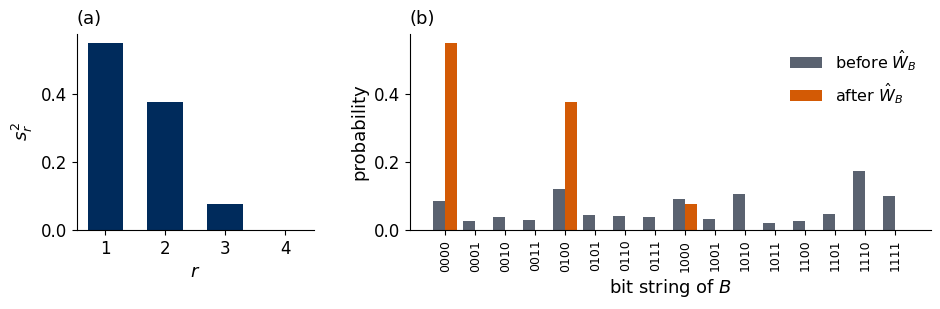

In [4]:
def schmidt_coefficients(psi, n_A, n):
    return np.linalg.svd(psi.reshape(2 ** n_A, 2 ** (n - n_A)), compute_uv=False)   # equation (6)

for eps in (0.0, EPS_EX):                                                       # encoded example, latent | trash cut
    s = schmidt_coefficients(U_EX @ example_state(eps), 1, 3)
    assert abs(np.sum(s ** 4) - FLOW[eps]["purity"]) < TOL                        # purity = sum of s_r^4
    print(f"epsilon = {eps:.1f}: squared Schmidt coefficients after the encoder {np.round(s ** 2, 4)}")

rng_s = np.random.default_rng(31)
N_A, N_B, CHI = 2, 4, 3
def random_orthonormal(d, r):
    return np.linalg.qr(rng_s.normal(size=(d, r)) + 1j * rng_s.normal(size=(d, r)))[0]
s_true = np.sort(rng_s.uniform(0.3, 1.0, CHI))[::-1]; s_true /= np.linalg.norm(s_true)
M_s = random_orthonormal(2 ** N_A, CHI) @ np.diag(s_true) @ random_orthonormal(2 ** N_B, CHI).T   # sum_r s_r |a_r>|b_r>
psi_s = M_s.reshape(-1)
U_s, s_s, Vh_s = np.linalg.svd(M_s)                                            # full SVD: Vh_s is a 16 x 16 unitary
assert np.sum(s_s > 1e-12) == CHI and np.allclose(s_s[:CHI], s_true, atol=TOL)

def compressor(m_keep):
    # W_B = (move the low m_keep qubits of B to the front) x (|b_r> -> |r>)
    perm = np.stack([e.reshape(2 ** (N_B - m_keep), 2 ** m_keep).T.reshape(-1) for e in np.eye(2 ** N_B)], axis=1)
    return perm @ Vh_s.conj()

m_needed = int(np.ceil(np.log2(CHI)))
best_keep = {}
for m_keep in range(N_B + 1):
    W = compressor(m_keep)
    assert np.allclose(W @ W.conj().T, np.eye(2 ** N_B), atol=TOL)
    out = (psi_s.reshape(2 ** N_A, 2 ** N_B) @ W.T).reshape(2 ** N_A, 2 ** m_keep, 2 ** (N_B - m_keep))
    best_keep[m_keep] = float(np.sum(np.abs(out[:, :, 0]) ** 2))                  # probability that the reset qubits are all 0
    assert abs(best_keep[m_keep] - np.sum(np.sort(s_s ** 2)[::-1][: 2 ** m_keep])) < TOL
assert abs(best_keep[m_needed] - 1) < TOL and best_keep[m_needed - 1] < 1 - 1e-3
print(f"Schmidt rank {CHI}: kept qubits of B and largest probability of resetting the rest without loss:",
      {m: round(v, 4) for m, v in best_keep.items()})
RESULTS["schmidt_subsystem"] = dict(chi=CHI, m_needed=m_needed, s2=(s_s[:CHI] ** 2).tolist(), best=best_keep)

W2 = compressor(m_needed)
pB_before = np.sum(np.abs(M_s) ** 2, axis=0)
pB_after = np.sum(np.abs(M_s @ W2.T) ** 2, axis=0)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9.6, 3.3), gridspec_kw=dict(width_ratios=[1, 2.2]))
a1.bar(np.arange(1, 5), np.r_[s_s[:4] ** 2], color=NAVY, width=0.6)
a1.set_xticks(range(1, 5)); a1.set_xlabel("$r$"); a1.set_ylabel(r"$s_r^2$")
xb = np.arange(2 ** N_B)
a2.bar(xb - 0.2, pB_before, width=0.4, color=GRAY, label=r"before $\hat W_B$")
a2.bar(xb + 0.2, pB_after, width=0.4, color=ORANGE, label=r"after $\hat W_B$")
a2.set_xticks(xb); a2.set_xticklabels([np.binary_repr(i, N_B) for i in xb], rotation=90, fontsize=9)
a2.set_xlabel("bit string of $B$"); a2.set_ylabel("probability"); a2.legend(frameon=False, loc="upper right")
for a, letter in ((a1, "a"), (a2, "b")):
    a.text(0.0, 1.03, f"({letter})", transform=a.transAxes, ha="left", va="bottom")
fig.tight_layout(w_pad=2.0); save(fig, "fig_lab070b_schmidt_rank"); plt.show()

Panel (a) shows the squared Schmidt coefficients of the random state, three of them non-zero. Panel (b) shows the probabilities of the bit strings of $B$ before and after $\hat W_B$. Before, the weight is spread over all sixteen strings. After, it sits on three strings whose last two bits are $00$, so the last two qubits of $B$ can be reset without changing the state, and four qubits of $B$ are compressed into $\lceil\log_2 3\rceil=2$. Keeping a single qubit of $B$ would lose the weight of the third Schmidt term. For the encoded three-qubit example the spectrum across the latent and trash qubits has a single coefficient for $\varepsilon=0$ and a second, small one for $\varepsilon=0.3$, which is the entanglement that the reset destroys. A trained encoder has to bring the Schmidt spectrum across the latent and trash qubits close to rank one, which we check after training in Section 7.

## 4. Ground states of the Ising chain

We compress ground states of the open transverse-field Ising chain,
$$\hat{\mathcal H}=-J\sum_{i=0}^{N-2}\hat Z_i\hat Z_{i+1}-h\sum_{i=0}^{N-1}\hat X_i , \tag{7}$$
with $J=1$ and $N=6$. The coupling favours neighbouring spins aligned along $z$, and the field $h$ favours every spin in $|+\rangle$. For $h\ll J$ the ground state is close to the cat state $(|0\dots0\rangle+|1\dots1\rangle)/\sqrt2$, for $h\gg J$ it is close to the product state $|+\rangle^{\otimes N}$, and in an infinite chain the two phases are separated by a transition at $h=J$. The Hamiltonian commutes with the parity $\hat\Pi=\prod_i\hat X_i$, which flips all spins, and the ground state is the even eigenstate, $\hat\Pi|\psi_0\rangle=+|\psi_0\rangle$. At $h=0$ the even and odd cat states are degenerate. We diagonalise $\hat{\mathcal H}-\hat\Pi$, which has the same eigenvectors as $\hat{\mathcal H}$ and lowers every even level by one, so its lowest eigenvector is the even ground state at every field.

As a reference for the entanglement we compute the half-chain entropy $S_{\rm vN}$ in bits, from the Schmidt coefficients of the cut between qubits 2 and 3. Qubit 0 is the most significant bit of the basis index.

In [5]:
N = 6
I2 = np.eye(2); X = np.array([[0., 1.], [1., 0.]]); Z = np.diag([1., -1.])

def op_on(ops):
    # Kronecker product with ops[q] on qubit q and the identity elsewhere; qubit 0 is the leftmost factor
    out = sp.identity(1, format="csr")
    for q in range(N):
        out = sp.kron(out, sp.csr_matrix(ops.get(q, I2)), format="csr")
    return out

ZZ = sum(op_on({i: Z, i + 1: Z}) for i in range(N - 1)).toarray()
XS = sum(op_on({i: X}) for i in range(N)).toarray()
PARITY = op_on({q: X for q in range(N)}).toarray()

def ground_state(h, J=1.0):
    w, v = np.linalg.eigh(-J * ZZ - h * XS - PARITY)      # equation (7) minus the parity: the even ground state
    psi = v[:, 0]
    return psi * np.sign(psi[np.argmax(np.abs(psi))])

def half_chain_entropy(psi):
    s = np.linalg.svd(psi.reshape(2 ** (N // 2), -1), compute_uv=False)
    lam = s[s > 1e-9] ** 2
    return float(-(lam * np.log2(lam)).sum())

H_SCAN = np.linspace(0.0, 2.0, 41)                         # fields of the later sweep
SCAN = np.array([ground_state(h) for h in H_SCAN])
S_SCAN = np.array([half_chain_entropy(p) for p in SCAN])
for p, h in zip(SCAN, H_SCAN):
    E0 = np.linalg.eigvalsh(-ZZ - h * XS)[0]
    assert abs(p @ (-ZZ - h * XS) @ p - E0) < TOL and abs(p @ PARITY @ p - 1) < TOL   # ground state, even parity
ghz = np.zeros(2 ** N); ghz[[0, -1]] = 1 / np.sqrt(2)
assert abs(abs(SCAN[0] @ ghz) - 1) < TOL                   # h = 0: the even cat state
print("S_vN (bits) at h = 0, 0.5, 1, 1.5, 2:", np.round(S_SCAN[::10], 3))

S_vN (bits) at h = 0, 0.5, 1, 1.5, 2: [1.    0.964 0.473 0.217 0.128]


The entropy falls from one bit, the value of the cat state at $h=0$, to about a tenth of a bit at $h=2$, where the state is close to a product state. In the finite chain the fall is smooth and steepest below $h=1$.

## 5. Compressing a family of states

A single known state is always compressible. Any normalised $|\psi\rangle$ is the first column of some unitary matrix, and the inverse of that unitary maps $|\psi\rangle$ to $|0\dots0\rangle$, so all $N$ qubits could be trash. Compression becomes a real task when one fixed encoder has to serve a whole family of states $|\psi_1\rangle,\dots,|\psi_M\rangle$, in our case ground states at $M$ different fields. The average over the family enters through the density matrix
$$\hat\rho=\frac1M\sum_{m=1}^M|\psi_m\rangle\langle\psi_m| , \tag{8}$$
a positive matrix with unit trace whose eigenvectors are the directions in which the family has weight and whose eigenvalues $\lambda_1\ge\lambda_2\ge\dots$ give the size of that weight. The trash fidelity of one state is the probability that all trash qubits are found in $0$ after the encoder, $F_{\rm trash}=\langle\psi|\hat U^\dagger\hat P_0\hat U|\psi\rangle$, with the projector $\hat P_0=\hat I_{\rm latent}\otimes|0\dots0\rangle\langle0\dots0|_{\rm trash}$ onto the states whose trash qubits are all $0$. Averaged over the family it becomes
$$\bar F_{\rm trash}=\mathrm{Tr}\big[\hat P_0\,\hat U\hat\rho\,\hat U^\dagger\big]\le\sum_{j=1}^{2^{N-k}}\lambda_j . \tag{9}$$
The projector $\hat P_0$ selects a subspace of dimension $2^{N-k}$, and the best any unitary can do is rotate the $2^{N-k}$ heaviest eigenvectors of $\hat\rho$ into it, which is Ky Fan's maximum principle [3]. A family is therefore compressible into $N-k$ qubits when the $2^{N-k}$ largest eigenvalues of $\hat\rho$ carry almost all the weight. This is the quantum analogue of principal component analysis, where a linear code keeps the directions of largest variance. The same eigenvalues are the squared Schmidt coefficients of the state $\frac{1}{\sqrt M}\sum_m|\psi_m\rangle\otimes|m\rangle$ that pairs each member with a label register, so the number of non-zero eigenvalues is a Schmidt rank.

A small example shows the bound at work. The one-qubit family $\{|0\rangle,|+\rangle\}$ cannot be compressed to zero qubits perfectly, since the two states differ. Its density matrix has the largest eigenvalue $\cos^2(\pi/8)\approx0.854$, and the rotation that takes the bisecting direction to $|0\rangle$ reaches this fidelity on average. For the Ising ground states parity adds a second exact statement. All ground states lie in the even sector of dimension $2^{N-1}$, so $\hat\rho$ has at most $2^{N-1}$ non-zero eigenvalues and one trash qubit can always be freed by an ideal encoder.

The cell checks these statements and evaluates the bound (9) for two families, eight ground states in the paramagnetic window $h\in[1.5,2]$, which we use for training, and 21 ground states spread over $h\in[0,2]$.

In [6]:
def ideal_fidelity(states, k):
    # right-hand side of equation (9): the 2^(N-k) largest eigenvalues of rho, equation (8)
    rho = states.T @ states.conj() / len(states)
    ev = np.sort(np.linalg.eigvalsh(rho))[::-1]
    return float(ev[: 2 ** (N - k)].sum())

# a single random state: a unitary with this state as first column, inverted, sends it to |0...0>
rng = np.random.default_rng(7)
psi = rng.normal(size=2 ** N) + 1j * rng.normal(size=2 ** N); psi /= np.linalg.norm(psi)
Q, _ = np.linalg.qr(np.column_stack([psi, rng.normal(size=(2 ** N, 2 ** N - 1))]))
assert abs(abs((Q.conj().T @ psi)[0]) - 1) < TOL

# the one-qubit example {|0>, |+>}
pair = np.array([[1, 0], [1, 1] / np.sqrt(2)])
lam_max = np.linalg.eigvalsh(pair.T @ pair / 2)[-1]
assert abs(lam_max - np.cos(np.pi / 8) ** 2) < TOL

WINDOW = (1.5, 2.0)
H_TRAIN = np.linspace(*WINDOW, 8)
TRAIN = np.array([ground_state(h) for h in H_TRAIN])
FULL = SCAN[::2]                                            # 21 states, h = 0, 0.1, ..., 2

# the ideal encoder: eigenvectors of rho, heaviest first, sent to the basis states whose trash bits are 0
k = 3
w, V = np.linalg.eigh(TRAIN.T @ TRAIN / len(TRAIN)); V = V[:, ::-1]
targets = [i for i in range(2 ** N) if i % 2 ** k == 0] + [i for i in range(2 ** N) if i % 2 ** k != 0]
U_ideal = np.zeros((2 ** N, 2 ** N)); U_ideal[targets, np.arange(2 ** N)] = 1; U_ideal = U_ideal @ V.T
assert np.allclose(U_ideal @ U_ideal.T, np.eye(2 ** N), atol=TOL)
F_ideal = np.mean([np.sum(np.abs((U_ideal @ s).reshape(-1, 2 ** k)[:, 0]) ** 2) for s in TRAIN])
assert abs(F_ideal - ideal_fidelity(TRAIN, k)) < TOL

KS = [1, 2, 3, 4, 5]
for name, fam in (("h in [1.5, 2]", TRAIN), ("h in [0, 2]  ", FULL)):
    assert abs(ideal_fidelity(fam, 1) - 1) < TOL            # parity: one trash qubit is always free
    print(name, " ideal 1 - F_trash for k = 1..5:", [f"{max(0, 1 - ideal_fidelity(fam, k)):.1e}" for k in KS])
RESULTS["ideal_infidelity_window"] = {k: max(0, 1 - ideal_fidelity(TRAIN, k)) for k in KS}
RESULTS["ideal_infidelity_full"] = {k: max(0, 1 - ideal_fidelity(FULL, k)) for k in KS}

h in [1.5, 2]  ideal 1 - F_trash for k = 1..5: ['0.0e+00', '0.0e+00', '0.0e+00', '5.8e-14', '8.9e-07']
h in [0, 2]    ideal 1 - F_trash for k = 1..5: ['0.0e+00', '0.0e+00', '1.0e-11', '8.5e-06', '6.0e-03']


The paramagnetic family fits into a single latent qubit, $k=5$, with an infidelity of about $10^{-6}$, because its eight states differ only by small corrections to $|+\rangle^{\otimes N}$. The family spread over both phases needs more room, and an ideal encoder loses about half a percent of the weight when it keeps one latent qubit. These are statements about the best unitary of all $2^N\times2^N$ unitaries. A circuit of limited depth may stay well below them, which we measure next.

## 6. Encoder circuit and cost functions

The encoder is the hardware-efficient ansatz (HEA) of the VQE notebook [4]. Starting from the input state, each of its $L$ layers applies $\hat R_z\hat R_y$ with independent angles to every qubit and then a chain of $\widehat{\rm CZ}$ gates on neighbouring pairs, and a final block of rotations closes the circuit. With $L=3$ it has $n=2N(L+1)=48$ angles. The decoder is the same circuit in reverse order with negated angles.

With the branches $|\alpha_t\rangle$ of the encoded state defined in Section 3, the trash fidelity is the weight of the branch $t=0\dots0$, $F_{\rm trash}=\langle\alpha_0|\alpha_0\rangle$. We train with two costs. The global cost
$$C_{\rm G}=1-\bar F_{\rm trash} \tag{10}$$
is the probability, averaged over the family, that at least one trash qubit is found in $1$. The local cost
$$C_{\rm L}=\frac1k\sum_{j\in{\rm trash}}\overline{P_j(1)} \tag{11}$$
averages the probability $P_j(1)$ that trash qubit $j$ alone is found in $1$. Both are read off measured bit strings of the trash qubits, $C_{\rm G}$ as the fraction of shots with any trash bit equal to $1$ and $C_{\rm L}$ as the mean fraction of $1$s per trash qubit. Each event counted in $C_{\rm L}$ is an event of $C_{\rm G}$, and the union bound sums the $k$ single-qubit probabilities, so
$$C_{\rm L}\le C_{\rm G}\le k\,C_{\rm L} , \tag{12}$$
and driving the local cost to zero drives the global cost to zero. The local cost matters for larger registers, where the gradients of global costs of random circuits become exponentially small in the number of measured qubits, while local costs of shallow circuits keep trainable gradients [5].

The quantity we care about in the end is the reconstruction fidelity $F_{\rm rec}$, the fidelity (2) of the output state after reset and decoding. Equation (4) bounds it from both sides by the trash fidelity,
$$F_{\rm trash}^2\le F_{\rm rec}\le F_{\rm trash} . \tag{13}$$
The lower bound keeps only the term $t=0$, and the upper bound follows from $|\langle\alpha_0|\alpha_t\rangle|^2\le\langle\alpha_0|\alpha_0\rangle\langle\alpha_t|\alpha_t\rangle$ and $\sum_t\langle\alpha_t|\alpha_t\rangle=1$. A trash fidelity close to one therefore guarantees a faithful reconstruction. The cell builds the encoder and checks equations (12) and (13) on random angles, with $F_{\rm rec}$ also computed from the explicit output density matrix.

In [7]:
L = 3
BITS = np.array(list(itertools.product([0, 1], repeat=N)))
CZ_CHAIN = jnp.asarray(np.prod([(-1.0) ** (BITS[:, q] * BITS[:, q + 1]) for q in range(N - 1)], axis=0).reshape((2,) * N))

def apply_1q(psi, U, q):
    return jnp.moveaxis(jnp.tensordot(U, psi, axes=([1], [q])), 0, q)
def ry(t):
    c, s = jnp.cos(t / 2), jnp.sin(t / 2)
    return jnp.array([[c, -s], [s, c]], dtype=jnp.complex128)
def rz(t):
    return jnp.diag(jnp.array([jnp.exp(-0.5j * t), jnp.exp(0.5j * t)]))
def rotations(psi, t):
    for q in range(N):
        psi = apply_1q(psi, rz(t[q, 1]) @ ry(t[q, 0]), q)
    return psi

def encode(theta, psi):
    # HEA with L layers, theta reshaped to (layer, qubit, [y, z]); the CZ chain is a diagonal sign
    th = theta.reshape(L + 1, N, 2)
    psi = psi.reshape((2,) * N).astype(jnp.complex128)
    psi, _ = lax.scan(lambda p, t: (rotations(p, t) * CZ_CHAIN, None), psi, th[:-1])
    return rotations(psi, th[-1]).reshape(-1)

def trash_fidelity(theta, psi, k):
    e = encode(theta, psi).reshape(2 ** (N - k), 2 ** k)     # column t holds the latent vector alpha_t
    return jnp.sum(jnp.abs(e[:, 0]) ** 2)

def local_cost(theta, psi, k):
    pr = jnp.abs(encode(theta, psi).reshape((2,) * N)) ** 2
    return jnp.mean(jnp.array([jnp.sum(jnp.take(pr, 1, axis=q)) for q in range(N - k, N)]))   # equation (11)

def reconstruction_fidelity(theta, psi, k):
    e = encode(theta, psi).reshape(2 ** (N - k), 2 ** k)
    return jnp.sum(jnp.abs(e[:, 0].conj() @ e) ** 2)          # equation (13)

th = jax.random.uniform(jax.random.PRNGKey(1), (2 * N * (L + 1),), minval=-np.pi, maxval=np.pi)
for k in (1, 2, 3):
    for s in (TRAIN[0], FULL[3]):
        F, CL, Fr = float(trash_fidelity(th, s, k)), float(local_cost(th, s, k)), float(reconstruction_fidelity(th, s, k))
        assert CL <= 1 - F + TOL and 1 - F <= k * CL + TOL         # equation (12) for one state
        assert F ** 2 - TOL <= Fr <= F + TOL                        # equation (13)
        e = np.asarray(encode(th, s)); E = e.reshape(2 ** (N - k), 2 ** k)
        zero = np.zeros((2 ** k, 2 ** k)); zero[0, 0] = 1
        rho_enc_out = np.kron(E @ E.conj().T, zero)                   # reset: latent density matrix times |0..0><0..0|
        assert abs(np.real(e.conj() @ rho_enc_out @ e) - Fr) < TOL   # <psi|U^dag rho U|psi> on the encoded side
assert abs(np.linalg.norm(np.asarray(encode(th, TRAIN[0]))) - 1) < TOL          # the encoder is unitary
print("equations (12) and (13) hold for random angles")

equations (12) and (13) hold for random angles


## 7. Training the encoder

We train on the eight paramagnetic ground states with $k=3$ trash qubits, once with the global cost (10) and once with the local cost (11). Exact gradients come from `jax.grad`, and the angles are updated by the Adam optimiser [6] written out in a few lines. Four starts with small random angles run in parallel, and we keep the start with the lowest final cost. In both runs we record the global infidelity $1-\bar F_{\rm trash}$, so the two curves measure the same quantity.

two trainings, 4 starts each: 9.4 s
final 1 - F_trash: global cost 1.5e-03, local cost 1.7e-03


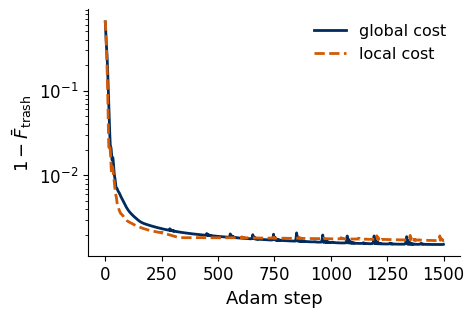

In [8]:
STEPS, LR, STARTS = 1500, 0.05, 4

def adam(loss, monitor, p, steps, lr, b1=0.9, b2=0.999, eps=1e-8):
    """Adam [6]; returns the final angles and (loss, monitor) before every step."""
    vg = jax.value_and_grad(loss)
    def step(c, t):
        p, m, v = c
        val, g = vg(p)
        m = b1 * m + (1 - b1) * g                      # running mean of the gradient
        v = b2 * v + (1 - b2) * g ** 2                 # running mean of its square
        p = p - lr * (m / (1 - b1 ** t)) / (jnp.sqrt(v / (1 - b2 ** t)) + eps)
        return (p, m, v), (val, monitor(p))
    (p, _, _), hist = lax.scan(step, (p, 0 * p, 0 * p), jnp.arange(1, steps + 1, dtype=jnp.float64))
    return p, hist

def train(k, cost="global", states=TRAIN):
    T = jnp.asarray(states)
    glob = lambda th: 1 - jnp.mean(jax.vmap(lambda s: trash_fidelity(th, s, k))(T))      # equation (10)
    loc = lambda th: jnp.mean(jax.vmap(lambda s: local_cost(th, s, k))(T))               # equation (11)
    loss = glob if cost == "global" else loc
    n = 2 * N * (L + 1)
    th0 = jnp.asarray(np.stack([np.random.default_rng(100 * k + s).normal(0, 0.1, n) for s in range(STARTS)]))
    P, (vals, mon) = jax.jit(jax.vmap(lambda t: adam(loss, glob, t, STEPS, LR)))(th0)
    best = int(np.argmin(np.asarray(vals[:, -1])))
    return dict(P=P, vals=np.asarray(vals), infid=np.asarray(mon), best=best)

t0 = time.perf_counter()
runs = {3: train(3)}
run_local = train(3, "local")
print(f"two trainings, {STARTS} starts each: {time.perf_counter() - t0:.1f} s")
g, l = runs[3], run_local
print(f"final 1 - F_trash: global cost {g['infid'][g['best'], -1]:.1e}, local cost {l['infid'][l['best'], -1]:.1e}")
RESULTS["k3_final_infidelity"] = {"global": float(g["infid"][g["best"], -1]), "local": float(l["infid"][l["best"], -1])}

fig, ax = plt.subplots()
ax.semilogy(g["infid"][g["best"]], color=NAVY, lw=2, label="global cost")
ax.semilogy(l["infid"][l["best"]], color=ORANGE, lw=2, ls="--", label="local cost")
ax.set_xlabel("Adam step"); ax.set_ylabel(r"$1-\bar F_{\rm trash}$")
ax.legend(frameon=False, loc="upper right")
save(fig, "fig_lab070b_training"); plt.show()

Both runs drop by more than two orders of magnitude within the first few hundred steps and end with an average infidelity of order $10^{-3}$. On six qubits with a shallow circuit the two costs train equally well, and the advantage of the local cost appears only for larger registers. The remaining infidelity is set by the circuit, since equation (9) allows an essentially perfect encoder for this family.

The Schmidt decomposition (6) shows what the training has achieved. For the encoder trained with the global cost we compute the squared Schmidt coefficients $s_r^2$ of each encoded training state across the cut between the three latent and the three trash qubits. The weight $F_{\rm trash}$ of the product branch $|\alpha_0\rangle\otimes|000\rangle$ can never exceed the weight $s_1^2$ of the best product state, so $1-s_1^2\le1-F_{\rm trash}$. For comparison we apply the same encoder to the cat-like ground state at $h=0$, which lies far outside the training family.

training states: largest 1 - s_1^2 = 1.1e-03, largest 1 - F_trash = 3.2e-03
ground state at h = 0: s_r^2 = [0.986 0.014 0.001 0.   ]


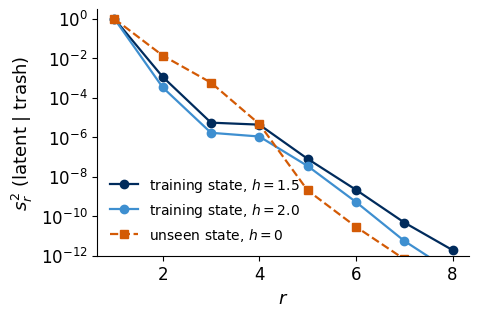

In [9]:
P_k3 = runs[3]["P"][runs[3]["best"]]
def encoded_spectrum(theta, psi, k):
    return np.linalg.svd(np.asarray(encode(theta, psi)).reshape(2 ** (N - k), 2 ** k), compute_uv=False) ** 2

spec_train = np.array([encoded_spectrum(P_k3, s, 3) for s in TRAIN])
F_tr = np.array([float(trash_fidelity(P_k3, s, 3)) for s in TRAIN])
assert np.all(1 - spec_train[:, 0] <= 1 - F_tr + TOL)                       # largest Schmidt weight >= trash fidelity
spec_h0 = encoded_spectrum(P_k3, SCAN[0], 3)
print(f"training states: largest 1 - s_1^2 = {np.max(1 - spec_train[:, 0]):.1e}, largest 1 - F_trash = {np.max(1 - F_tr):.1e}")
print(f"ground state at h = 0: s_r^2 = {np.round(spec_h0[:4], 3)}")
RESULTS["schmidt_trained_k3"] = dict(max_one_minus_s1sq=float(np.max(1 - spec_train[:, 0])),
                                     max_one_minus_Ftrash=float(np.max(1 - F_tr)), h0_spectrum=spec_h0.tolist())

fig, ax = plt.subplots()
r = np.arange(1, 2 ** 3 + 1)
for j, c in ((0, NAVY), (len(TRAIN) - 1, BLUE)):
    ax.semilogy(r, np.maximum(spec_train[j], 1e-16), "o-", color=c, lw=1.6, ms=6, label=f"training state, $h={H_TRAIN[j]:.1f}$")
ax.semilogy(r, np.maximum(spec_h0, 1e-16), "s--", color=ORANGE, lw=1.6, ms=6, label="unseen state, $h=0$")
ax.set_xlabel("$r$"); ax.set_ylabel(r"$s_r^2$ (latent | trash)"); ax.set_ylim(1e-12, 3)
ax.legend(frameon=False, fontsize=10, loc="lower left")
save(fig, "fig_lab070b_schmidt_trained"); plt.show()

The figure shows the squared Schmidt coefficients across the latent and trash qubits on a logarithmic scale, largest first, for two training states and for the unseen state at $h=0$. For the training states the first coefficient carries almost all the weight and the others are smaller by orders of magnitude, so the encoded states are nearly products of a latent and a trash state, and the reset loses almost nothing. The cat-like state at $h=0$ keeps second and third coefficients that are larger by one to two orders of magnitude, so it stays weakly entangled across the cut. Its first coefficient still carries almost all the weight, while its anomaly score in Section 9 is large. The encoder turns this state into a near product whose trash part differs from $|000\rangle$, and the reset then replaces that trash part. A small Schmidt rank across the cut is therefore necessary for compression, and the trash qubits must in addition end in $|0\dots0\rangle$.

## 8. Compressibility and the number of trash qubits

We now train encoders for $k=1,\dots,5$, once on the paramagnetic family and once on the family spread over $h\in[0,2]$, and compare the trained infidelity with the ideal value from equation (9).

ten trainings: 52.2 s
trained 1 - F_trash, h in [1.5, 2]: ['1.9e-04', '1.1e-03', '1.5e-03', '2.8e-03', '3.2e-03']
trained 1 - F_trash, h in [0, 2]:   ['1.7e-02', '5.3e-02', '9.4e-02', '1.2e-01', '1.7e-01']


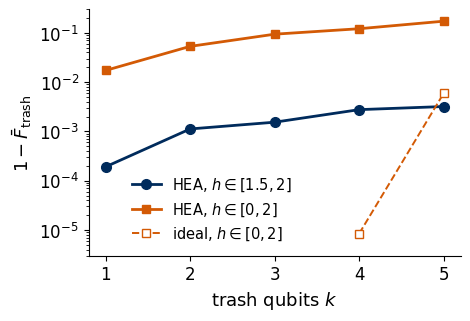

In [10]:
t0 = time.perf_counter()
for k in KS:
    runs.setdefault(k, train(k))
runs_full = {k: train(k, states=FULL) for k in KS}
print(f"ten trainings: {time.perf_counter() - t0:.1f} s")
trained = {k: float(runs[k]["infid"][runs[k]["best"], -1]) for k in KS}
trained_full = {k: float(runs_full[k]["infid"][runs_full[k]["best"], -1]) for k in KS}
for k in KS:
    assert trained_full[k] >= RESULTS["ideal_infidelity_full"][k] - TOL       # no circuit beats equation (9)
print("trained 1 - F_trash, h in [1.5, 2]:", [f"{trained[k]:.1e}" for k in KS])
print("trained 1 - F_trash, h in [0, 2]:  ", [f"{trained_full[k]:.1e}" for k in KS])
RESULTS["trained_infidelity_window"], RESULTS["trained_infidelity_full"] = trained, trained_full

fig, ax = plt.subplots()
ax.semilogy(KS, [trained[k] for k in KS], "o-", color=NAVY, lw=2, ms=7, label=r"HEA, $h\in[1.5,2]$")
ax.semilogy(KS, [trained_full[k] for k in KS], "s-", color=ORANGE, lw=2, ms=6, label=r"HEA, $h\in[0,2]$")
kb = [k for k in KS if RESULTS["ideal_infidelity_full"][k] > 1e-9]
ax.semilogy(kb, [RESULTS["ideal_infidelity_full"][k] for k in kb], "s--", color=ORANGE, mfc="white", lw=1.4, ms=6,
            label=r"ideal, $h\in[0,2]$")
ax.set_xticks(KS); ax.set_xlabel("trash qubits $k$"); ax.set_ylabel(r"$1-\bar F_{\rm trash}$"); ax.set_ylim(3e-6, 0.3)
ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(0.08, 0.0), fontsize=10.5)
save(fig, "fig_lab070b_compressibility"); plt.show()

The figure shows the average trash infidelity after training against the number of trash qubits, on a logarithmic scale. The ideal values for $k\le3$ and all ideal values of the paramagnetic family lie below $10^{-6}$ and are off the scale. The paramagnetic family stays near $10^{-3}$ for every $k$, so the trained circuit compresses it into a single qubit almost as well as into five. The family that crosses the transition is harder by one to two orders of magnitude, and its infidelity grows with $k$. For $k\le4$ an ideal encoder would compress it almost perfectly, so this gap is a limitation of the three-layer circuit. A short circuit disentangles the nearly product states of the paramagnet easily, while undoing the cat-like correlations of the ordered states and serving both kinds of state with the same angles demands more.

## 9. A frozen autoencoder as an anomaly detector

We take the encoders trained on the paramagnetic family with $k=2$ and $k=3$, keep their angles fixed and evaluate the anomaly score $1-F_{\rm trash}$ for the ground state at each of the 41 fields between $0$ and $2$ [2]. No information about the ordered phase enters the training. The figure also shows the spread over the four starts and, in the second panel, the exact half-chain entropy.

k = 2: score at h = 0, 0.5, 1, 1.5, 2: [0.581 0.299 0.04  0.002 0.001];  at h = 0 over the starts 0.49 to 0.58
k = 3: score at h = 0, 0.5, 1, 1.5, 2: [0.587 0.306 0.043 0.003 0.001];  at h = 0 over the starts 0.59 to 0.69


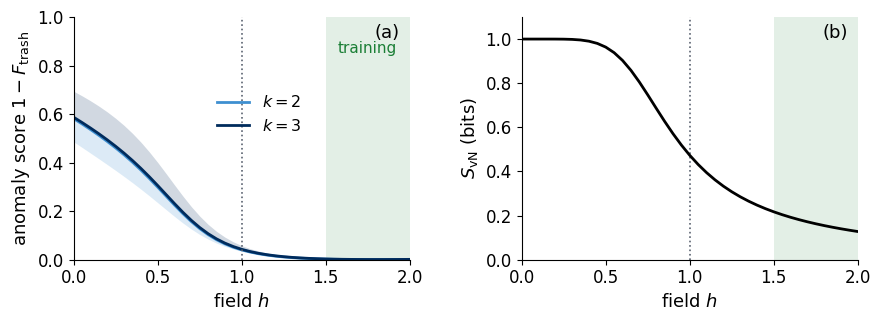

In [11]:
def scan_scores(theta, k):
    return np.asarray(jax.vmap(lambda s: 1 - trash_fidelity(theta, s, k))(jnp.asarray(SCAN)))

scores = {k: np.array([scan_scores(runs[k]["P"][s], k) for s in range(STARTS)]) for k in (2, 3)}
rec = {k: np.asarray(jax.vmap(lambda s: 1 - reconstruction_fidelity(runs[k]["P"][runs[k]["best"]], s, k))(jnp.asarray(SCAN)))
       for k in (2, 3)}
for k in (2, 3):
    b = scores[k][runs[k]["best"]]
    assert np.all(rec[k] >= b - TOL) and np.all(rec[k] <= 1 - (1 - b) ** 2 + TOL)      # equation (13)
    print(f"k = {k}: score at h = 0, 0.5, 1, 1.5, 2: {np.round(b[::10], 3)};  at h = 0 over the starts "
          f"{scores[k][:, 0].min():.2f} to {scores[k][:, 0].max():.2f}")
RESULTS["anomaly_score_kept_start"] = {k: dict(zip(np.round(H_SCAN, 2).tolist(), scores[k][runs[k]["best"]].tolist())) for k in (2, 3)}

fig, (a1, a2) = plt.subplots(1, 2, figsize=(9.0, 3.4))
for k, c in ((2, BLUE), (3, NAVY)):
    a1.fill_between(H_SCAN, scores[k].min(0), scores[k].max(0), color=c, alpha=0.18, lw=0)
    a1.plot(H_SCAN, scores[k][runs[k]["best"]], color=c, lw=2, label=f"$k={k}$")
for a, letter in ((a1, "a"), (a2, "b")):
    a.axvspan(*WINDOW, color=GREEN, alpha=0.12, lw=0)
    a.axvline(1.0, color=GRAY, ls=":", lw=1.2)
    a.set_xlabel("field $h$"); a.set_xlim(0, 2)
    a.text(0.97, 0.97, f"({letter})", transform=a.transAxes, ha="right", va="top")
a1.set_ylabel(r"anomaly score $1-F_{\rm trash}$"); a1.set_ylim(0, 1)
a1.legend(frameon=False, loc="center right", bbox_to_anchor=(0.72, 0.6))
a1.text(1.75, 0.85, "training", color=GREEN, ha="center", fontsize=11)
a2.plot(H_SCAN, S_SCAN, color="black", lw=2)
a2.set_ylabel(r"$S_{\rm vN}$ (bits)"); a2.set_ylim(0, 1.1)
fig.tight_layout(w_pad=2.0)
save(fig, "fig_lab070b_anomaly"); plt.show()

Panel (a) shows the score of the kept start as a line and the range over the four starts as a band, with the training window shaded green and the critical field of the infinite chain dotted. The score stays at the training level across the whole paramagnetic side, starts to rise near $h=1$ and climbs to about $0.6$ at $h=0$. Panel (b) shows that the half-chain entropy rises over the same range of fields. The frozen encoder thus separates the two regimes of the chain without being shown the ordered phase and without an order parameter. In a chain of six qubits both curves change smoothly, and locating the transition itself would require a comparison of several chain lengths.

Part of the score is physics and part belongs to the circuit. An encoder that had learned only the single-qubit rotation taking $|+\rangle$ to $|0\rangle$ would give the cat state of $h=0$ a score of $1-2^{-k}$, since each trash qubit of the cat state then reads $0$ or $1$ with equal probability. The trained encoders stay below this value, and the four starts, which all compress the training family equally well, give scores at $h=0$ that differ by about a tenth. The behaviour of an encoder on states it never saw depends on how its circuit treats directions outside the training family, which training does not fix. The position where the score starts to rise is common to all starts and follows the entanglement, whereas its height deep in the ordered phase depends on the circuit and the random start.

In [12]:
RESULTS["runtime_seconds"] = time.perf_counter() - started
(RES / "lab070b_results.json").write_text(json.dumps(RESULTS, indent=2, default=float))
print(f"results written to {RES / 'lab070b_results.json'}")
print(f"runtime of the classroom route (Sections 1 to 9): {RESULTS['runtime_seconds']:.1f} s")
def sci(x, digits=1):
    m, e = f"{x:.{digits}e}".split("e")
    return f"{m}\\times10^{{{int(e)}}}"
def write_macros(extra=None):
    mac = {"N": N, "L": L, "NParams": 2 * N * (L + 1), "Steps": STEPS, "Starts": STARTS,
           "FlowEps": EPS_EX, "FlowF": f"{FLOW[EPS_EX]['F']:.3f}", "FlowPurity": f"{FLOW[EPS_EX]['purity']:.3f}",
           "FlowDH": f"{FLOW[EPS_EX]['D_H']:.3f}", "FlowBound": f"{FLOW[EPS_EX]['bound']:.3f}",
           "SchmidtChi": CHI, "SchmidtKeep": m_needed, "SchmidtOneQubit": f"{best_keep[m_needed - 1]:.3f}",
           "TrainedOneMinusSOne": sci(RESULTS["schmidt_trained_k3"]["max_one_minus_s1sq"]),
           "IdealFullKFive": sci(RESULTS["ideal_infidelity_full"][5]), "IdealWindowKFive": sci(RESULTS["ideal_infidelity_window"][5]),
           "KThreeGlobal": sci(RESULTS["k3_final_infidelity"]["global"]), "KThreeLocal": sci(RESULTS["k3_final_infidelity"]["local"]),
           "TrainedWindowKFive": sci(RESULTS["trained_infidelity_window"][5]), "TrainedFullKFive": sci(RESULTS["trained_infidelity_full"][5]),
           "ScoreKTwoHZero": f"{RESULTS['anomaly_score_kept_start'][2][0.0]:.2f}",
           "ScoreKThreeHZero": f"{RESULTS['anomaly_score_kept_start'][3][0.0]:.2f}",
           "Runtime": f"{RESULTS['runtime_seconds']:.0f}"}
    mac.update(extra or {})
    with open(FIG / "nb_numbers_lab070b.tex", "w") as f:
        for key, val in mac.items():
            assert key.isalpha(), key
            f.write(f"\\newcommand{{\\labseventyb{key}}}{{{val}}}\n")
    return mac
print("numbers:", write_macros())

results written to classroom_results/lab070b_results.json
runtime of the classroom route (Sections 1 to 9): 84.4 s
numbers: {'N': 6, 'L': 3, 'NParams': 48, 'Steps': 1500, 'Starts': 4, 'FlowEps': 0.3, 'FlowF': '0.868', 'FlowPurity': '0.901', 'FlowDH': '0.083', 'FlowBound': '0.697', 'SchmidtChi': 3, 'SchmidtKeep': 2, 'SchmidtOneQubit': '0.924', 'TrainedOneMinusSOne': '1.1\\times10^{-3}', 'IdealFullKFive': '6.0\\times10^{-3}', 'IdealWindowKFive': '8.9\\times10^{-7}', 'KThreeGlobal': '1.5\\times10^{-3}', 'KThreeLocal': '1.7\\times10^{-3}', 'TrainedWindowKFive': '3.2\\times10^{-3}', 'TrainedFullKFive': '1.7\\times10^{-1}', 'ScoreKTwoHZero': '0.58', 'ScoreKThreeHZero': '0.59', 'Runtime': '84'}


## 10. Optional. Phase maps with eight qubits

This section is optional and runs for four to ten minutes on a laptop CPU, depending on its load. It repeats the study on a larger scale, with $N=8$ qubits, an encoder of $p=4$ HEA layers ($n=80$ angles) and the trash qubits again at the end of the chain. Every QAE here is trained on a single ground state with the local cost (11), which on a single state is the trash Hamming distance $D_H$, the mean number of $1$s per trash qubit. Each training uses 800 Adam steps and four random starts, of which we keep the one with the lowest $D_H$. The next cell writes the functions of this section to a small module `qae_phase_helpers.py` in the folder of the notebook, and the cell after it imports the module as `qp`. A separate module keeps the eight-qubit names, such as `N`, `encode` and `BITS`, apart from the six-qubit ones of the earlier sections, which the exercises still use. Besides $D_H$ we record the reconstruction fidelity $F=F_{\rm rec}$ of equation (13) and the trash entropy $S_B$, the entropy in bits of the reduced density matrix $\hat\rho_B$ of the trash qubits after the encoder. $S_B$ measures the entanglement between latent and trash qubits that the encoder failed to remove, and it vanishes for perfect compression.

Three studies follow. In the pointwise map a fresh QAE is trained at every point of a parameter scan, so it measures how compressible each ground state is for this circuit. Besides the Ising chain we scan the XXZ chain
$$\hat{\mathcal H}_{\rm XXZ}=J\sum_{i=0}^{N-2}\big(\hat X_i\hat X_{i+1}+\hat Y_i\hat Y_{i+1}+\Delta\,\hat Z_i\hat Z_{i+1}\big) , \tag{14}$$
with $J=1$ and the anisotropy $\Delta$ between $-2$ and $3$. It is ferromagnetic for $\Delta<-1$, has a gapless region with long-range correlations for $-1<\Delta<1$ and orders antiferromagnetically (Néel order) for $\Delta>1$. In the anomaly maps six QAEs with $k=3$ are trained at reference points of the XXZ chain in a transverse field,
$$\hat{\mathcal H}=\hat{\mathcal H}_{\rm XXZ}+h_x\sum_{i=0}^{N-1}\hat X_i , \tag{15}$$
frozen and evaluated with $D_H$ over a grid of $24\times25$ points in the plane of $\Delta\in[-2,2]$ and $h_x\in[0,2.5]$ [2]. Exact ground-state observables on the same grid serve as the reference. The last study looks at the Schmidt spectrum across the cut between latent and trash qubits after the encoder. At degenerate points we keep the ground state that is even under $\hat\Pi$, and the grids avoid the points $\Delta=\pm1$ and $\Delta=0$ exactly.

In [ ]:
%%writefile qae_phase_helpers.py
"""Helpers for the optional Section 10 of Lab 070b: quantum autoencoders (QAE) for N = 8 spin chains.

Models (open chains, J = 1):
  TFIM            H = -J sum Z_i Z_{i+1} - h sum X_i
  XXZ             H =  J sum (X_i X_{i+1} + Y_i Y_{i+1} + Delta Z_i Z_{i+1})
  XXZ + field     H =  J sum (X_i X_{i+1} + Y_i Y_{i+1} + Delta Z_i Z_{i+1}) + h_x sum X_i
Ground states by dense diagonalisation of H - 1e-6 * Parity (selects the even member of an exactly degenerate doublet;
grids avoid the SU(2) point Delta = -1 where the ground level is a multiplet).
Encoder: hardware-efficient ansatz, p = 4 layers of Rz Ry on every qubit + CZ chain, closing Rz Ry block (80 angles).
Trash = last k qubits. Training loss = trash Hamming distance D_H = (1/k) sum_j P_j(1) (local cost).
Adam (hand-written), exact jax.grad, all points and random starts trained in parallel with vmap; CPU, float64.
Diagnostics: reconstruction fidelity F = sum_t |<alpha_0|alpha_t>|^2, D_H, trash entropy S_B (bits).
"""
import os
os.environ["JAX_PLATFORMS"] = "cpu"
import itertools
import time
import numpy as np
import scipy.sparse as sp
import jax
import jax.numpy as jnp
from jax import lax
import matplotlib.pyplot as plt

jax.config.update("jax_enable_x64", True)
NAVY, BLUE, ORANGE, GRAY, GREEN = "#002B5C", "#3E8FD0", "#D35A05", "#5A6270", "#1B7F36"
K_COLORS = {1: BLUE, 3: NAVY, 5: ORANGE, 7: GREEN}
RC = {"font.size": 13, "axes.labelsize": 13, "xtick.labelsize": 12, "ytick.labelsize": 12, "legend.fontsize": 12,
      "axes.spines.top": False, "axes.spines.right": False, "savefig.bbox": "tight", "pdf.fonttype": 42}

# ---------------- settings ----------------
N, P = 8, 4                                   # qubits, encoder layers
STEPS, LR, STARTS = 800, 0.05, 4
KS_POINTWISE = [1, 3, 5, 7]
H_TFIM = np.linspace(0.0, 2.0, 21)
D_XXZ = np.linspace(-2.0, 3.0, 22)            # step 0.238: avoids Delta = -1 and Delta = 1 exactly
D_MAP = np.linspace(-2.0, 2.0, 24)            # step 0.174: avoids Delta = -1, 0, 1 exactly
HX_MAP = np.linspace(0.0, 2.5, 25)
K_ANOM = 3
REFERENCES = {"ferromagnet": (-1.6, 0.2), "XY": (0.0, 0.2), "Néel": (1.6, 0.2),
              "canted ferro": (-1.6, 1.4), "canted Néel": (1.6, 1.4), "paramagnet": (0.0, 2.3)}
H_SCHMIDT = [0.0, 0.5, 1.0, 2.0]

# ---------------- exact ground states ----------------
I2 = np.eye(2); X = np.array([[0., 1.], [1., 0.]]); Y = np.array([[0., -1j], [1j, 0.]]); Z = np.diag([1., -1.])


def op_on(ops):
    out = sp.identity(1, format="csr")
    for q in range(N):
        out = sp.kron(out, sp.csr_matrix(ops.get(q, I2)), format="csr")
    return out


ZZB = sum(op_on({i: Z, i + 1: Z}) for i in range(N - 1)).toarray().real
XYB = (sum(op_on({i: X, i + 1: X}) + op_on({i: Y, i + 1: Y}) for i in range(N - 1))).toarray().real
XS = sum(op_on({i: X}) for i in range(N)).toarray().real
PARITY = op_on({q: X for q in range(N)}).toarray().real


def ground_state(H):
    w, v = np.linalg.eigh(H - 1e-6 * PARITY)
    psi = v[:, 0]
    return psi * np.sign(psi[np.argmax(np.abs(psi))])


def tfim(h):
    return -ZZB - h * XS


def xxz(delta, hx=0.0):
    return XYB + delta * ZZB + hx * XS


def half_chain_entropy(psi):
    s = np.linalg.svd(psi.reshape(2 ** (N // 2), -1), compute_uv=False)
    lam = s[s > 1e-12] ** 2
    return float(-(lam * np.log2(lam)).sum())


# ---------------- encoder and diagnostics ----------------
BITS = np.array(list(itertools.product([0, 1], repeat=N)))
CZ_CHAIN = jnp.asarray(np.prod([(-1.0) ** (BITS[:, q] * BITS[:, q + 1]) for q in range(N - 1)], axis=0).reshape((2,) * N))
N_ANGLES = 2 * N * (P + 1)


def _apply_1q(psi, U, q):
    return jnp.moveaxis(jnp.tensordot(U, psi, axes=([1], [q])), 0, q)


def _rot(psi, t):
    for q in range(N):
        c, s = jnp.cos(t[q, 0] / 2), jnp.sin(t[q, 0] / 2)
        U = jnp.diag(jnp.array([jnp.exp(-0.5j * t[q, 1]), jnp.exp(0.5j * t[q, 1])])) @ jnp.array([[c, -s], [s, c]])
        psi = _apply_1q(psi, U, q)
    return psi


def encode(theta, psi):
    th = theta.reshape(P + 1, N, 2)
    psi = psi.reshape((2,) * N).astype(jnp.complex128)
    psi, _ = lax.scan(lambda a, t: (_rot(a, t) * CZ_CHAIN, None), psi, th[:-1])
    return _rot(psi, th[-1]).reshape(-1)


def hamming(theta, psi, k):
    """trash Hamming distance D_H: mean probability of bit 1 on the last k qubits"""
    pr = jnp.abs(encode(theta, psi).reshape(2 ** (N - k), 2 ** k)) ** 2
    ones = jnp.asarray(BITS[: 2 ** k, N - k:].sum(axis=1), dtype=jnp.float64)   # number of 1s in each trash string
    return jnp.sum(pr.sum(axis=0) * ones) / k


def diagnostics(theta, psi, k):
    """reconstruction fidelity F, D_H, trash entropy S_B (bits), Schmidt spectrum across latent|trash"""
    E = encode(theta, psi).reshape(2 ** (N - k), 2 ** k)          # column t = latent vector alpha_t
    F = jnp.sum(jnp.abs(E[:, 0].conj() @ E) ** 2)
    rhoB = E.T @ E.conj()
    lam = jnp.clip(jnp.linalg.eigvalsh(rhoB), 1e-300, 1.0)
    SB = -jnp.sum(jnp.where(lam > 1e-14, lam * jnp.log2(lam), 0.0))
    return F, hamming(theta, psi, k), SB, jnp.sort(lam)[::-1]


def _adam(loss, p, steps, lr, b1=0.9, b2=0.999, eps=1e-8):
    vg = jax.value_and_grad(loss)

    def step(c, t):
        p, m, v = c
        val, g = vg(p)
        m = b1 * m + (1 - b1) * g
        v = b2 * v + (1 - b2) * g ** 2
        p = p - lr * (m / (1 - b1 ** t)) / (jnp.sqrt(v / (1 - b2 ** t)) + eps)
        return (p, m, v), val
    (p, _, _), vals = lax.scan(step, (p, 0 * p, 0 * p), jnp.arange(1, steps + 1, dtype=jnp.float64))
    return p, vals


def train_points(states, k, seed=0, steps=STEPS, lr=LR, starts=STARTS):
    """a fresh QAE for every state (D_H loss), `starts` random starts each, all in one vmap; returns the best angles"""
    states = jnp.asarray(states)
    M = states.shape[0]
    rng = np.random.default_rng(seed + 1000 * k)
    th0 = jnp.asarray(rng.normal(0, 0.1, (M, starts, N_ANGLES)))
    one = lambda t, s: _adam(lambda th: hamming(th, s, k), t, steps, lr)
    run = jax.jit(jax.vmap(jax.vmap(one, in_axes=(0, None)), in_axes=(0, 0)))
    Pm, vals = run(th0, states)
    final = jax.vmap(jax.vmap(lambda t, s: hamming(t, s, k), in_axes=(0, None)))(Pm, states)
    best = np.asarray(jnp.argmin(final, axis=1))
    return Pm[np.arange(M), best], np.asarray(vals)[np.arange(M), best]


def eval_points(thetas, states, k):
    """diagnostics of angle set i on state i"""
    f = jax.jit(jax.vmap(lambda t, s: diagnostics(t, s, k)))
    return [np.asarray(a) for a in f(jnp.asarray(thetas), jnp.asarray(states))]


def eval_frozen(theta, states, k):
    f = jax.jit(jax.vmap(lambda s: diagnostics(theta, s, k)))
    return [np.asarray(a) for a in f(jnp.asarray(states))]


# ---------------- experiments ----------------
def compute_pointwise(ks=KS_POINTWISE):
    out = {}
    for model, grid, ham in (("TFIM", H_TFIM, tfim), ("XXZ", D_XXZ, xxz)):
        states = np.array([ground_state(ham(g)) for g in grid])
        out[model] = dict(grid=grid, states=states, S=np.array([half_chain_entropy(s) for s in states]))
        for k in ks:
            t0 = time.perf_counter()
            th, _ = train_points(states, k)
            F, DH, SB, _ = eval_points(th, states, k)
            out[model][k] = dict(theta=np.asarray(th), F=F, DH=DH, SB=SB, seconds=time.perf_counter() - t0)
    return out


def compute_map():
    states = np.empty((len(HX_MAP), len(D_MAP), 2 ** N))
    obs = {"X": np.empty(states.shape[:2]), "ZZ": np.empty(states.shape[:2]), "S": np.empty(states.shape[:2])}
    for i, hx in enumerate(HX_MAP):
        for j, d in enumerate(D_MAP):
            s = ground_state(xxz(d, hx))
            states[i, j] = s
            obs["X"][i, j] = s @ XS @ s / N
            obs["ZZ"][i, j] = s @ ZZB @ s / (N - 1)
            obs["S"][i, j] = half_chain_entropy(s)
    ref_states = np.array([ground_state(xxz(d, hx)) for d, hx in REFERENCES.values()])
    t0 = time.perf_counter()
    th, _ = train_points(ref_states, K_ANOM, seed=7)
    train_seconds = time.perf_counter() - t0
    flat = states.reshape(-1, 2 ** N)
    maps = {}
    for name, t in zip(REFERENCES, th):
        F, DH, SB, _ = eval_frozen(t, flat, K_ANOM)
        maps[name] = dict(DH=DH.reshape(states.shape[:2]), F=F.reshape(states.shape[:2]))
    ref_DH = {name: float(eval_frozen(t, s[None], K_ANOM)[1][0]) for name, t, s in zip(REFERENCES, th, ref_states)}
    return dict(obs=obs, maps=maps, ref_DH=ref_DH, train_seconds=train_seconds)


def compute_schmidt(pointwise):
    """Schmidt spectra across latent|trash (k = 3): fresh encoders at each h, and the encoder trained at h = 2 frozen"""
    d = pointwise["TFIM"]
    idx = [int(np.argmin(np.abs(d["grid"] - h))) for h in H_SCHMIDT]
    fresh = eval_points(d[3]["theta"][idx], d["states"][idx], 3)[3]
    frozen = eval_frozen(d[3]["theta"][-1], d["states"][idx], 3)[3]
    return dict(h=H_SCHMIDT, fresh=fresh, frozen=frozen)


# ---------------- figures ----------------
def plot_pointwise(pw, path, ks=KS_POINTWISE):
    with plt.rc_context(RC):
        fig, axs = plt.subplots(3, 2, figsize=(7.6, 6.6), sharex="col")
        for c, (model, xl) in enumerate((("TFIM", "field $h$"), ("XXZ", r"anisotropy $\Delta$"))):
            d = pw[model]
            for k in ks:
                kw = dict(color=K_COLORS.get(k, GRAY), lw=1.8, marker="o", ms=3)
                axs[0, c].plot(d["grid"], d[k]["F"], label=f"$k={k}$", **kw)
                axs[1, c].plot(d["grid"], d[k]["DH"], **kw)
                axs[2, c].plot(d["grid"], d[k]["SB"], **kw)
            axs[2, c].plot(d["grid"], d["S"], color="black", ls="--", lw=1.6, label=r"$S_{\rm vN}$ half chain")
            axs[0, c].set_title(model, fontsize=13)
            axs[2, c].set_xlabel(xl)
            for a in axs[:, c]:
                a.axvline(1.0 if model == "TFIM" else -1.0, color=GRAY, ls=":", lw=1)
                if model == "XXZ":
                    a.axvline(1.0, color=GRAY, ls=":", lw=1)
        axs[0, 0].set_ylabel("$F$"); axs[1, 0].set_ylabel("$D_H$"); axs[2, 0].set_ylabel(r"$S_B$ (bits)")
        hs, ls = axs[0, 0].get_legend_handles_labels()
        h2, l2 = axs[2, 1].get_legend_handles_labels()
        fig.tight_layout(h_pad=0.6, w_pad=1.2)
        fig.legend(hs + h2, ls + l2, loc="lower center", bbox_to_anchor=(0.5, 0.995), ncol=5, frameon=False,
                   fontsize=11.5, handlelength=1.5, columnspacing=1.0)
        fig.savefig(path, dpi=220); plt.close(fig)


def _heat(ax, Zm, vmin, vmax, cmap):
    return ax.pcolormesh(D_MAP, HX_MAP, Zm, shading="nearest", cmap=cmap, vmin=vmin, vmax=vmax, rasterized=True)


def plot_anomaly_maps(mp, path):
    with plt.rc_context(RC):
        fig, axs = plt.subplots(2, 3, figsize=(8.4, 5.4), sharex=True, sharey=True)
        vmax = max(m["DH"].max() for m in mp["maps"].values())
        for ax, (name, (d, hx)) in zip(axs.flat, REFERENCES.items()):
            im = _heat(ax, mp["maps"][name]["DH"], 0, vmax, "cividis")
            ax.plot(d, hx, marker="*", ms=16, color="white", mec="black", mew=0.8)
            ax.set_title(name, fontsize=12)
        for a in axs[1]:
            a.set_xlabel(r"$\Delta$")
        for a in axs[:, 0]:
            a.set_ylabel("$h_x$")
        fig.tight_layout(w_pad=0.6, h_pad=0.8)
        cb = fig.colorbar(im, ax=axs, shrink=0.85, pad=0.02)
        cb.set_label(r"$D_H$ of frozen QAE ($k=3$)", fontsize=12)
        fig.savefig(path, dpi=220); plt.close(fig)


def plot_observables(mp, path):
    with plt.rc_context(RC):
        fig, axs = plt.subplots(1, 3, figsize=(9.6, 3.2), sharey=True)
        specs = (("X", r"$\langle\hat X_i\rangle$", -1, 0, "cividis"), ("ZZ", r"$\langle\hat Z_i\hat Z_{i+1}\rangle$", -1, 1, "RdBu_r"),
                 ("S", r"$S_{\rm vN}$ (bits)", 0, None, "magma"))
        for ax, (key, lab, lo, hi, cm) in zip(axs, specs):
            im = _heat(ax, mp["obs"][key], lo, hi, cm)
            cb = fig.colorbar(im, ax=ax, pad=0.02); cb.set_label(lab, fontsize=12)
            ax.set_xlabel(r"$\Delta$")
        axs[0].set_ylabel("$h_x$")
        fig.tight_layout(w_pad=0.8)
        fig.savefig(path, dpi=220); plt.close(fig)


def plot_schmidt(sc, path):
    with plt.rc_context(RC):
        fig, axs = plt.subplots(1, 2, figsize=(7.0, 3.0), sharey=True)
        r = np.arange(1, 2 ** 3 + 1)
        cols = [ORANGE, GREEN, BLUE, NAVY]
        for ax, key, title in ((axs[0], "fresh", "trained at each $h$"), (axs[1], "frozen", "trained at $h=2$")):
            for h, c, spec in zip(sc["h"], cols, sc[key]):
                ax.semilogy(r, np.clip(spec, 1e-12, 1), "o-", color=c, lw=1.6, ms=5, label=f"$h={h:g}$")
            ax.set_xlabel("Schmidt index $r$"); ax.set_title(title, fontsize=12); ax.set_xticks(r)
            ax.set_ylim(1e-10, 2)
        axs[0].set_ylabel(r"$s_r^2$ (latent | trash)")
        axs[1].legend(frameon=False, fontsize=10.5, loc="lower left")
        fig.tight_layout(w_pad=1.0)
        fig.savefig(path, dpi=220); plt.close(fig)


def numbers(pw, mp, sc, seconds):
    L = [f"N = {N}, HEA p = {P} layers ({N_ANGLES} angles), trash = last k qubits, loss D_H, Adam {STEPS} steps lr {LR}, "
         f"{STARTS} starts per point (best D_H kept)"]
    L.append(f"pointwise grids: TFIM h in [0,2] {len(H_TFIM)} pts; XXZ Delta in [-2,3] {len(D_XXZ)} pts; k = {KS_POINTWISE}")
    for model in ("TFIM", "XXZ"):
        d = pw[model]
        for k in KS_POINTWISE:
            i = int(np.argmin(d[k]["F"]))
            L.append(f"{model} k={k}: min F = {d[k]['F'].min():.3f} at {d['grid'][i]:.2f}; mean F = {d[k]['F'].mean():.3f}; "
                     f"max D_H = {d[k]['DH'].max():.3f}; max S_B = {d[k]['SB'].max():.3f} bits; train {d[k]['seconds']:.0f} s")
        L.append(f"{model} half-chain S_vN: min {d['S'].min():.3f}, max {d['S'].max():.3f} bits")
    L.append(f"anomaly map: Delta in [-2,2] {len(D_MAP)} x h_x in [0,2.5] {len(HX_MAP)} = {len(D_MAP) * len(HX_MAP)} points, k = {K_ANOM}; "
             f"training of {len(REFERENCES)} references {mp['train_seconds']:.0f} s")
    for name, (d, hx) in REFERENCES.items():
        m = mp["maps"][name]["DH"]
        L.append(f"  ref {name} (Delta={d}, h_x={hx}): D_H at reference {mp['ref_DH'][name]:.1e}; map max {m.max():.3f}; "
                 f"fraction of grid with D_H < 0.05: {np.mean(m < 0.05):.2f}")
    for h, a, b in zip(sc["h"], sc["fresh"], sc["frozen"]):
        L.append(f"Schmidt (TFIM, k=3) h={h}: fresh s_1^2 = {a[0]:.6f}, 1-s_1^2 = {1 - a[0]:.1e}; "
                 f"frozen(h=2) s_1^2 = {b[0]:.4f}, 1-s_1^2 = {1 - b[0]:.1e}")
    L.append(f"runtime {seconds:.0f} s (CPU)")
    return "\n".join(L) + "\n"

N = 8, HEA p = 4 layers (80 angles), trash = last k qubits, loss D_H, Adam 800 steps lr 0.05, 4 starts per point (best D_H kept)
pointwise grids: TFIM h in [0,2] 21 pts; XXZ Delta in [-2,3] 22 pts; k = [1, 3, 5, 7]
TFIM k=1: min F = 1.000 at 0.70; mean F = 1.000; max D_H = 0.000; max S_B = 0.001 bits; train 19 s
TFIM k=3: min F = 0.972 at 0.60; mean F = 0.996; max D_H = 0.005; max S_B = 0.125 bits; train 21 s
TFIM k=5: min F = 0.970 at 0.40; mean F = 0.992; max D_H = 0.006; max S_B = 0.132 bits; train 18 s
TFIM k=7: min F = 0.979 at 0.70; mean F = 0.994; max D_H = 0.003; max S_B = 0.072 bits; train 18 s
TFIM half-chain S_vN: min 0.128, max 1.000 bits
XXZ k=1: min F = 0.978 at -0.81; mean F = 0.998; max D_H = 0.011; max S_B = 0.086 bits; train 19 s
XXZ k=3: min F = 0.912 at -0.81; mean F = 0.984; max D_H = 0.020; max S_B = 0.353 bits; train 17 s
XXZ k=5: min F = 0.643 at -0.81; mean F = 0.942; max D_H = 0.067; max S_B = 0.696 bits; train 18 s
XXZ k=7: min F = 0.878 at -0.81; mean F = 0.

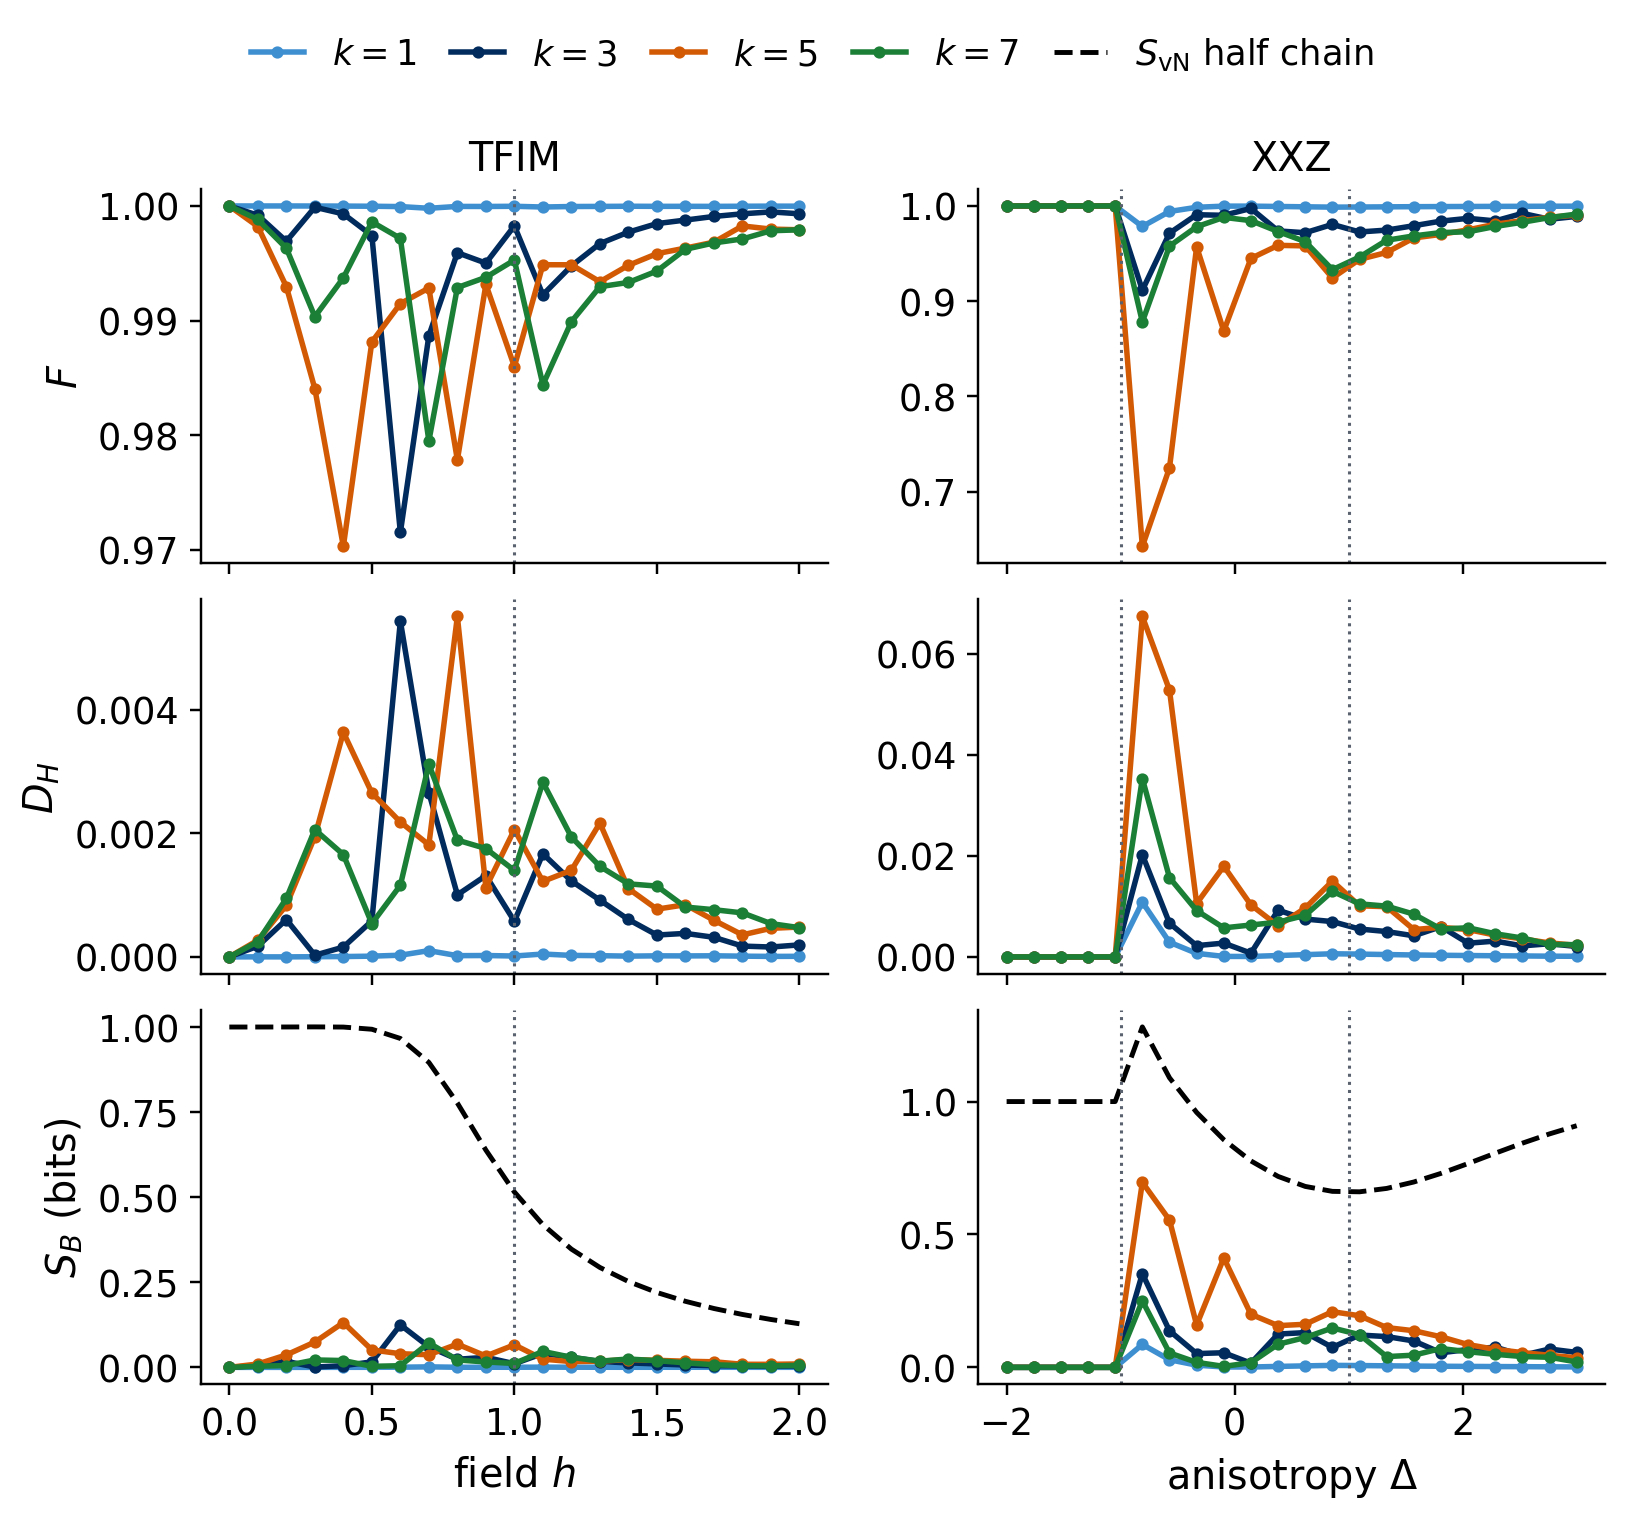

In [13]:
from IPython.display import Image, display
import qae_phase_helpers as qp              # N = 8 helpers: ground states, HEA encoder (p = 4), D_H training, diagnostics

t_opt = time.perf_counter()
pw = qp.compute_pointwise()                 # fresh QAE at every point, k = 1, 3, 5, 7
mp = qp.compute_map()                       # six frozen QAEs (k = 3) on the (Delta, h_x) grid, exact observables
sc = qp.compute_schmidt(pw)                 # Schmidt spectra across latent | trash, Ising chain, k = 3
for d in (pw["TFIM"], pw["XXZ"]):
    for k in qp.KS_POINTWISE:
        assert np.all(d[k]["F"] <= 1 + TOL) and np.all(d[k]["F"] >= np.maximum(0, 1 - k * d[k]["DH"]) ** 2 - TOL)   # eqs. (12), (13)
print(qp.numbers(pw, mp, sc, time.perf_counter() - t_opt))
for name, fn, data in (("pointwise", qp.plot_pointwise, pw), ("anomaly_maps", qp.plot_anomaly_maps, mp),
                       ("observables_map", qp.plot_observables, mp), ("schmidt", qp.plot_schmidt, sc)):
    for ext in ("png", "pdf"):
        fn(data, FIG / f"fig_lab070b_{name}.{ext}")
RESULTS["optional_seconds"] = time.perf_counter() - t_opt
display(Image(str(FIG / "fig_lab070b_pointwise.png"), width=620))

The left column shows the Ising chain against $h$ and the right column the XXZ chain against $\Delta$, with one line per number of trash qubits and the exact half-chain entropy dashed in the bottom row. Each point is a separately trained circuit. For the Ising chain every ground state is compressed with $F$ above $0.97$ at every $k$, including the cat states of the ordered side, which four layers disentangle completely. The small dips scatter from point to point and from one $k$ to the next, so they reflect the optimisation more than the state. The XXZ chain is compressed perfectly in the ferromagnetic region, where the ground state is a cat state of all spins up and all spins down. The fidelity drops and $S_B$ rises sharply just above $\Delta=-1$, where the half-chain entropy is largest, and compression stays imperfect across the gapless region. A larger trash register should never compress better than a smaller one, so the better results at $k=7$ than at $k=5$ show that four random starts do not always find the best angles of this circuit.

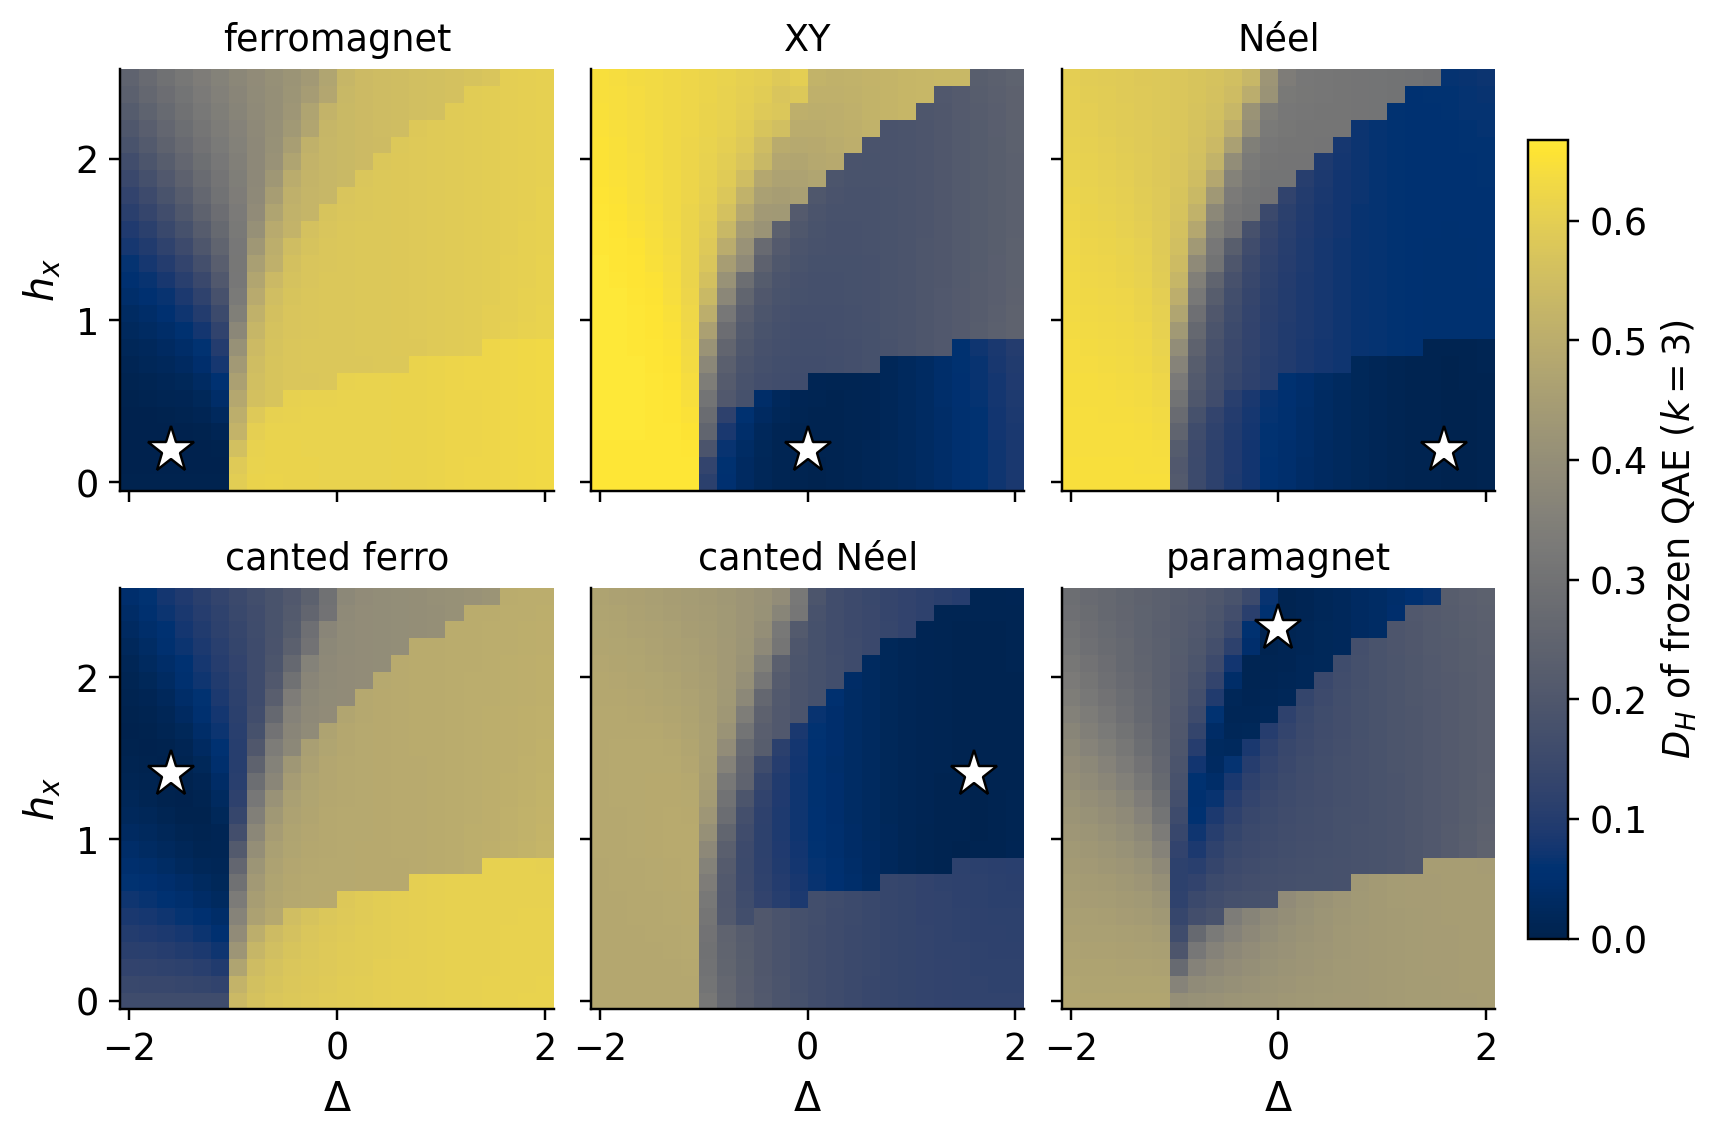

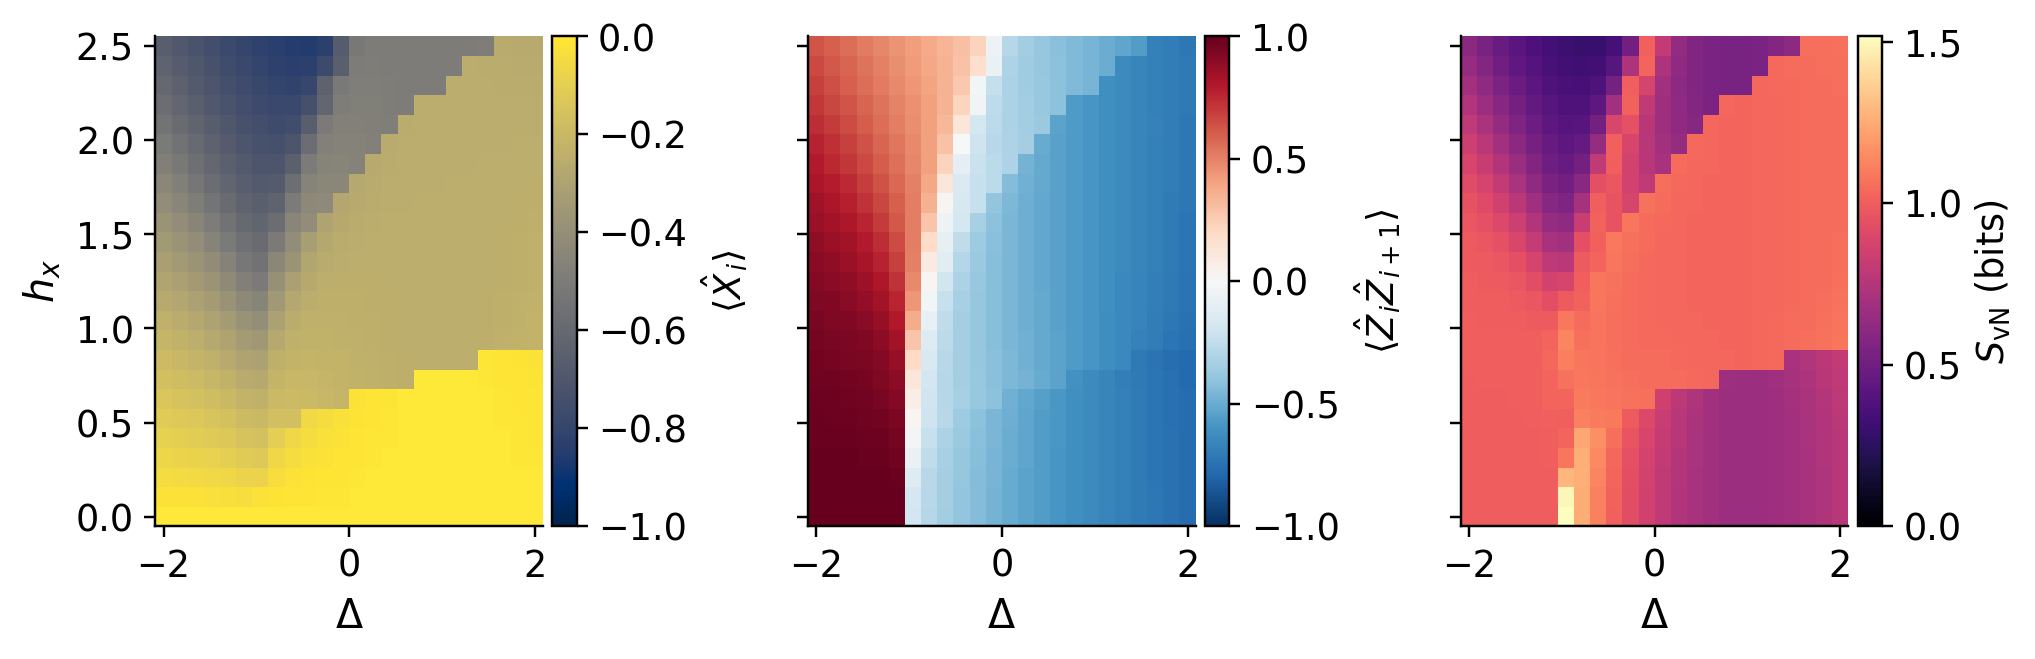

In [14]:
display(Image(str(FIG / "fig_lab070b_anomaly_maps.png"), width=620))
display(Image(str(FIG / "fig_lab070b_observables_map.png"), width=700))

Each panel of the first figure belongs to one frozen QAE, trained at the point marked by the star, and shows its $D_H$ over the whole plane, dark where the state is compressed as well as at the reference and bright where it fails. Every encoder generalises over a connected region around its reference, and the borders of these regions coincide with the structures in the exact observables below, the magnetisation $\langle\hat X_i\rangle$ along the field (negative, because the field term has a plus sign), the nearest-neighbour correlation $\langle\hat Z_i\hat Z_{i+1}\rangle$ and the half-chain entropy. The vertical border at $\Delta=-1$ separates the ferromagnet from the rest at small fields. The tilted borders on the right follow steps in the observables, which in a chain of eight qubits come from crossings of the lowest levels as the field grows. These dark regions mark finite-size regimes of the eight-qubit chain, and whether their borders converge to phase transitions could be decided only by repeating the maps for several chain lengths. No order parameter enters the training, and each map needs one training instead of one per grid point.

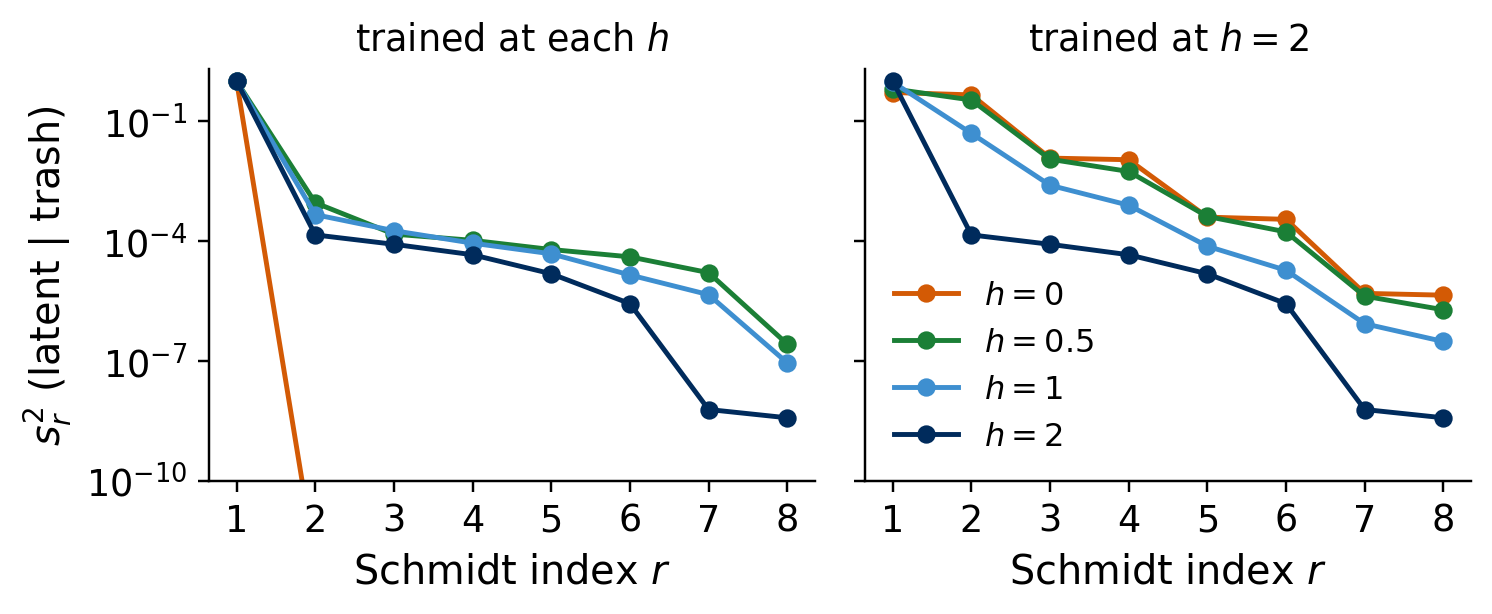

optional section: 194 s
numbers: {'N': 6, 'L': 3, 'NParams': 48, 'Steps': 1500, 'Starts': 4, 'FlowEps': 0.3, 'FlowF': '0.868', 'FlowPurity': '0.901', 'FlowDH': '0.083', 'FlowBound': '0.697', 'SchmidtChi': 3, 'SchmidtKeep': 2, 'SchmidtOneQubit': '0.924', 'TrainedOneMinusSOne': '1.1\\times10^{-3}', 'IdealFullKFive': '6.0\\times10^{-3}', 'IdealWindowKFive': '8.9\\times10^{-7}', 'KThreeGlobal': '1.5\\times10^{-3}', 'KThreeLocal': '1.7\\times10^{-3}', 'TrainedWindowKFive': '3.2\\times10^{-3}', 'TrainedFullKFive': '1.7\\times10^{-1}', 'ScoreKTwoHZero': '0.58', 'ScoreKThreeHZero': '0.59', 'Runtime': '84', 'OptTfimKThreeMinF': '0.972', 'OptXxzKFiveMinF': '0.643', 'OptSeconds': '194'}


In [15]:
display(Image(str(FIG / "fig_lab070b_schmidt.png"), width=620))
RESULTS["optional_numbers"] = qp.numbers(pw, mp, sc, RESULTS["optional_seconds"]).splitlines()
(RES / "lab070b_results.json").write_text(json.dumps(RESULTS, indent=2, default=float))
print(f"optional section: {RESULTS['optional_seconds']:.0f} s")
opt = {line.split(":")[0].strip(): line for line in RESULTS["optional_numbers"]}
def min_fid(line):
    return line.split("min F = ")[1].split(" ")[0]
print("numbers:", write_macros({"OptTfimKThreeMinF": min_fid(opt["TFIM k=3"]), "OptXxzKFiveMinF": min_fid(opt["XXZ k=5"]),
                                "OptSeconds": f"{RESULTS['optional_seconds']:.0f}"}))

The figure shows the squared Schmidt coefficients $s_r^2$ of the encoded Ising ground state across the cut between the five latent and the three trash qubits, largest first. With an encoder trained at the same field (left) the spectrum is dominated by one coefficient, with the remaining weight of order $10^{-3}$ or smaller, and at $h=0$ it is exactly of rank one. The encoded state is then nearly a product of a latent and a trash state, which is the condition for compression. The encoder trained at $h=2$ and applied at smaller fields (right) leaves a spread spectrum. At $h=0$ the first two coefficients are almost equal, so latent and trash qubits share about one bit of entanglement, and at $h=0.5$ the second coefficient still carries about a third of the weight. No reset of the trash qubits can preserve such a state.

## 11. Exercises

1. Train the encoder on the ordered family $h\in[0.2,0.5]$ with $k=2$, freeze it and repeat the sweep of Section 9. Compare the score at $h=2$ with the value $1-2^{-k}$ that an encoder built only from controlled-NOT gates would give the state $|+\rangle^{\otimes N}$.
2. Repeat the sweep of Section 9 with the encoder trained on the local cost (11). Check equation (12) along the sweep and decide whether the anomaly score depends on the cost used in training.
3. Shots. On a device $F_{\rm trash}$ is estimated as the fraction $\tilde F_{\rm trash}$ of $S$ measured bit strings whose trash bits are all $0$. Sample $\tilde F_{\rm trash}$ for $S=100$ and $S=1000$ along the sweep and find the smallest $S$ for which the rise of the score below $h=1$ stands out from the shot noise.
4. Use the middle qubits 2 and 3 as trash qubits instead of the last two and repeat Sections 7 and 9. Explain the change with the entanglement across the middle of the chain.
5. Train the family $h\in[0,2]$ with $L=5$ instead of $L=3$ and compare the infidelities with the ideal values of Section 5.

## 12. Summary

A quantum autoencoder compresses states by an encoder circuit that drives $k$ trash qubits to $|0\rangle$, so that they can be reset and the remaining $N-k$ qubits hold the state. Any single state can be compressed completely, and the meaningful task is to compress a family of states with one encoder. The density matrix of the family sets the limit, since the best average trash fidelity equals the sum of its $2^{N-k}$ largest eigenvalues. The trash fidelity is measured on the trash qubits alone, either as a global cost or as an average of single-qubit probabilities, and it bounds the reconstruction fidelity from both sides. For six-qubit Ising ground states a three-layer hardware-efficient encoder compresses paramagnetic states into a single qubit with an infidelity of order $10^{-3}$, whereas a family that spans both phases is compressed markedly worse than an ideal encoder would allow. An encoder trained in the paramagnet and then frozen fails on ordered states, and its anomaly score rises where the half-chain entropy rises. The onset of this rise reflects the change of the ground states, while the height of the score in the unseen phase depends on the circuit and its random start. All numbers are exact state-vector results, whereas a device would estimate the trash fidelity from measured bit strings.

## References

[1] J. Romero, J. P. Olson, and A. Aspuru-Guzik, Quantum autoencoders for efficient compression of quantum data, Quantum Sci. Technol. **2**, 045001 (2017), [doi:10.1088/2058-9565/aa8072](https://doi.org/10.1088/2058-9565/aa8072).

[2] K. Kottmann, F. Metz, J. Fraxanet, and N. Baldelli, Variational quantum anomaly detection: Unsupervised mapping of phase diagrams on a physical quantum computer, Phys. Rev. Research **3**, 043184 (2021), [doi:10.1103/PhysRevResearch.3.043184](https://doi.org/10.1103/PhysRevResearch.3.043184).

[3] K. Fan, On a theorem of Weyl concerning eigenvalues of linear transformations I, Proc. Natl. Acad. Sci. USA **35**, 652 (1949), [doi:10.1073/pnas.35.11.652](https://doi.org/10.1073/pnas.35.11.652).

[4] A. Kandala, A. Mezzacapo, K. Temme, M. Takita, M. Brink, J. M. Chow, and J. M. Gambetta, Hardware-efficient variational quantum eigensolver for small molecules and quantum magnets, Nature **549**, 242 (2017), [doi:10.1038/nature23879](https://doi.org/10.1038/nature23879).

[5] M. Cerezo, A. Sone, T. Volkoff, L. Cincio, and P. J. Coles, Cost function dependent barren plateaus in shallow parametrized quantum circuits, Nat. Commun. **12**, 1791 (2021), [doi:10.1038/s41467-021-21728-w](https://doi.org/10.1038/s41467-021-21728-w).

[6] D. P. Kingma and J. Ba, Adam: A method for stochastic optimization, [arXiv:1412.6980](https://arxiv.org/abs/1412.6980) (2014).